# **Ant Life-Cycle Simulation and Machine Learning**
***
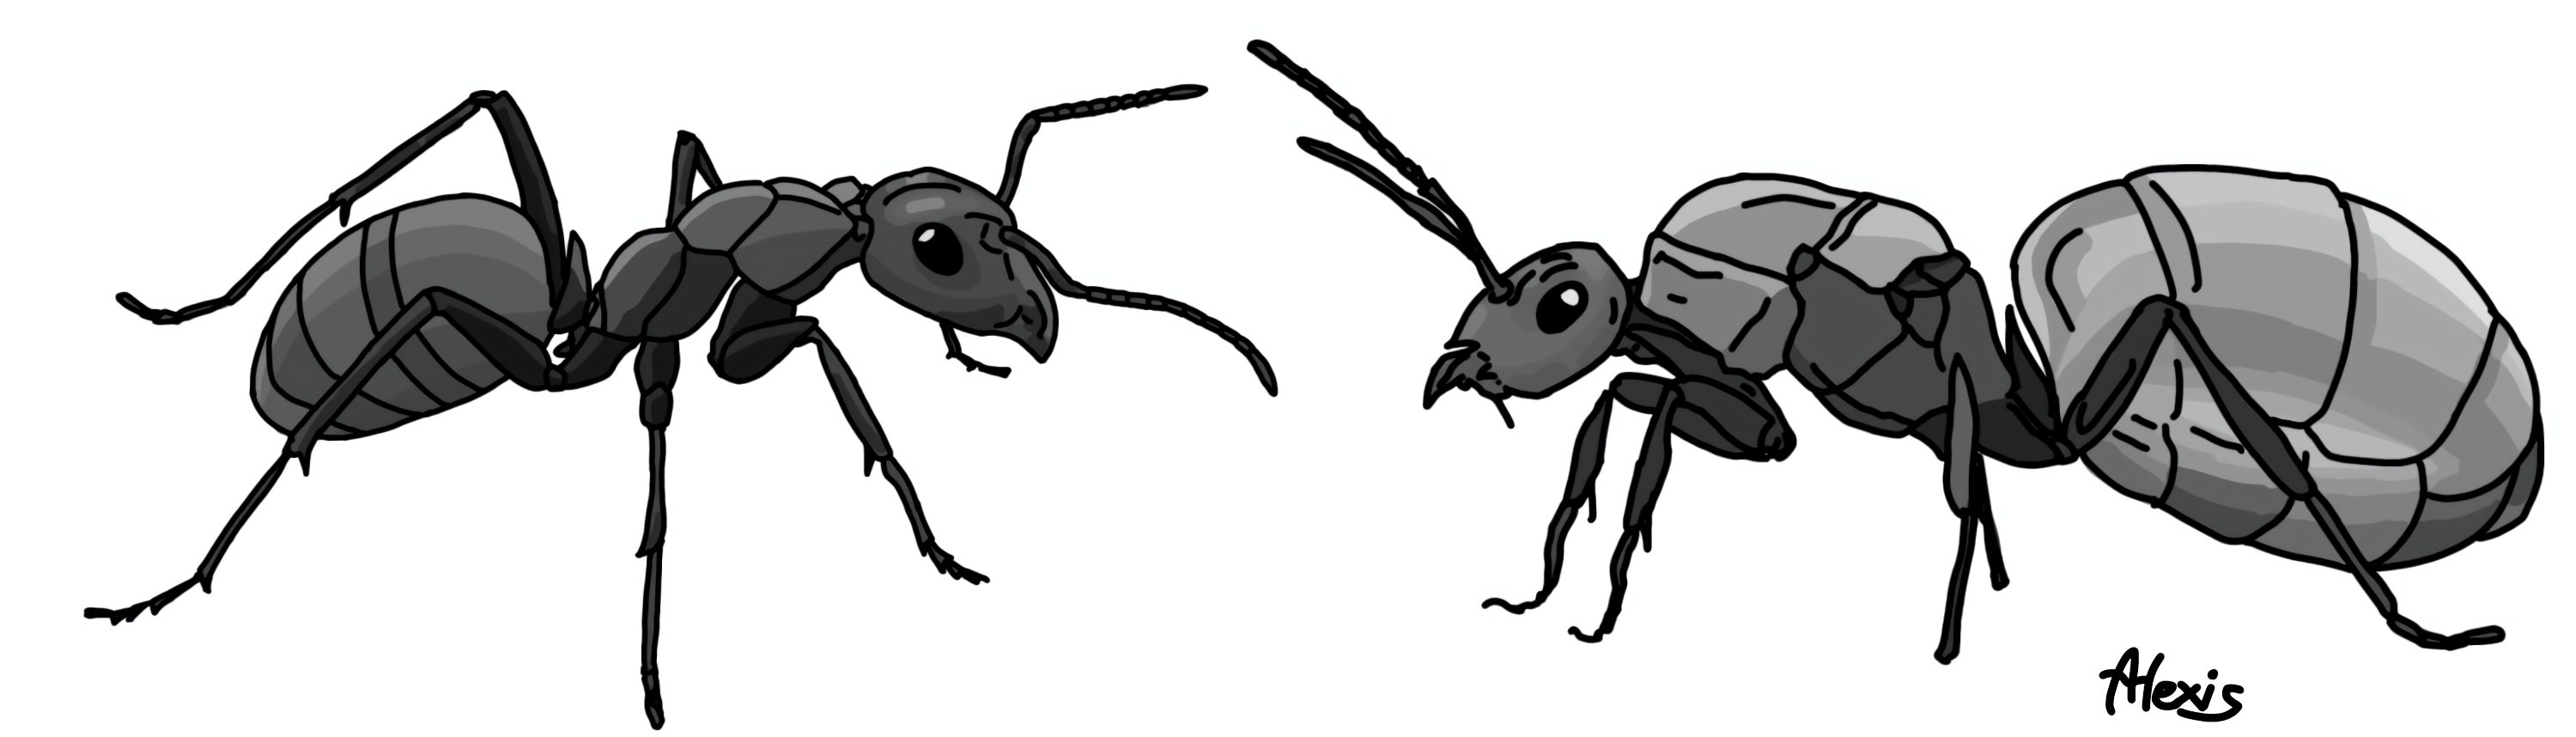
***

**Predicting when a rare, *de novo* allele can persist in a social-insect metapopulation**

## **Overview**

Ant colonies contain two castes, **queens** and **workers**, that share the same genome but are selected towards different phenotypic optima. A newly arisen allele can therefore be beneficial in one caste and costly in the other. Whether such an allele is eventually **lost**, **fixed**, or **maintained as a polymorphism** depends on two groups of factors: the *ecology* of the colonies (survival, extinction, migration, number of queens and of mating males) and the *genetics* of the allele (its effect and its dominance in each caste).

Answering this question directly requires an individual-based life-cycle simulation, and that is expensive: every combination of parameters is run for 100 replicates of 10,000 generations. This notebook uses **machine learning as a tool to understand the simulation**. We proceed in four steps:

1. **Describe** the simulation and the dataset it produced.
2. **Explore, balance and prepare** the data for a binary classification task: *is polymorphism maintained or not?*
3. **Train and compare** five classifiers of increasing flexibility: logistic regression, decision tree, random forest, XGBoost and a multilayer perceptron.
4. **Interpret** the best model with SHAP to find out which parameters drive polymorphism, and test a specific hypothesis about dominance in queens and workers.

## **Contents**

1. Setup
2. The Simulation Model and the Dataset
3. Data Loading and Cleaning
4. Exploratory Data Analysis
5. Data Preparation
6. Modelling Strategy
7. Logistic Regression
8. Decision Tree
9. Random Forest
10. XGBoost
11. Multilayer Perceptron
11. Interpreting XGBoost with SHAP
13. Model Comparison and Conclusions

> **Reading guide.** Blocks labelled **Takeaway** summarise what the preceding result tells us. Blocks labelled **Note** give practical or methodological context.

## **1. Setup**

### **1.1 Libraries, Custom Script and Random Seed**

The cell below imports every library used in the notebook, grouped by purpose, and loads the custom script `ant_dataset_generator.py`. That script generates the simulation data by drawing each parameter at random within its biological range (see Section 2).

It also detects whether the notebook runs in **Google Colab**. If so, the script is downloaded automatically from the project's GitHub repository; if not, it must sit in the same folder as the notebook. Finally, a fixed **random seed** (`random_seed = 5`) makes the data reduction, the train/test split and every hyperparameter search reproducible.

In [ ]:
### --- Libraries for General Use --- ###
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

### --- Libraries for Adaptive Data Loading --- ###
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

### --- Loading Script for Data Generation --- ###
# This custom script generates data based on random sampling of each feature within its biological range.
if IN_COLAB and not os.path.exists('dataset_generator_simple_model.py'):
    !wget https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/dataset_generator_simple_model.py

### --- Libraries to Hide Warnings --- ###
import warnings
from sklearn.exceptions import DataConversionWarning
warnings.filterwarnings(action = 'ignore', category = DataConversionWarning)
warnings.filterwarnings(action = 'ignore', category = UserWarning)

### --- Libraries for Data Transformation --- ###
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

### --- Libraries for Models' Hyperparameters Tuning --- ###
from sklearn.model_selection import RandomizedSearchCV

### --- Libraries for Logistic Regression --- ###
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, 
                             roc_curve, confusion_matrix)

### --- Libraries for Decision Tree --- ###
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

### --- Libraries for Random Forest --- ###
from sklearn.ensemble import RandomForestClassifier

### --- Libraries for XGBoost --- ###
from xgboost import XGBClassifier

### --- Libraries for Neural Networks --- ###
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance

### --- Libraries for Model Interpretation (SHAP) --- ###
import shap

### --- Libraries for Sparse Data and Statistics --- ###
from scipy import sparse
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import fisher_exact

### --- Random Seed --- ###
random_seed = 5

/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### **1.2 Helper Plotting Functions**

The same figures are needed several times (once per model, for instance), so they are wrapped in six small helper functions. Defining them once keeps the rest of the notebook short and the figures consistent.

| Function | What it displays |
|---|---|
| `barplot_polymorphic_or_not` | Fraction of non polymorphic versus polymorphic samples. |
| `plot_feature_distr` | Distribution of every feature, drawn separately for polymorphic and non polymorphic samples. |
| `plot_feature_pairwise_corr` | Correlation matrix of all the features and the response variable. |
| `plot_confusion_matrix` | Confusion matrix of a fitted model on a chosen data set (train or test), with TN, FP, FN and TP as percentages. |
| `plot_roc` | ROC curve and area under the curve (AUC) of a fitted model on a chosen data set. |
| `feat_imp_plot` | Top 10 feature importances of a fitted tree ensemble, using the names produced by the preprocessor. |

In [3]:
### --- Polymorphic Versus Non Polymorphic Barplot Helper --- ###
def barplot_polymorphic_or_not(df, polymorph_threshold = 0.0):
    """Bar plot of the non polymorphic versus polymorphic share of the samples.

    polymorph_threshold is the minimum value of `frac_polymorphic` for a sample to be
    called polymorphic. With 0.0, a single replicate in which the allele was maintained
    is enough. Feel free to play with it.
    """
    # Identify all the polymorphic cases.
    polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)

    # Create the barplot of the non polymorphic versus polymorphic fraction.
    fig, ax = plt.subplots()
    ax.bar([0, 1], [1 - polymorph_samples.mean().item(), polymorph_samples.mean().item()],
           color = 'skyblue')
    ax.set_xticks(ticks = [0, 1], labels = ['Non Polymorphic', 'Polymorphic'])
    ax.set_ylabel('Fraction of Samples')
    ax.set_title('Non-Polymorphic vs Polymorphic Fraction', fontweight = 'bold', pad = 15)
    plt.show()


### --- Features Distribution Plotting Helper --- ###
def plot_feature_distr(df, params, polymorph_threshold = 0.0):
    """Histogram of every feature, drawn separately for polymorphic and non polymorphic samples."""
    # Separate the non polymorphic from the polymorphic samples.
    polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)

    fig, axs = plt.subplots(nrows = 3, ncols = 4, figsize = (15, 12))
    for i, col_name in enumerate(params):
        ax = axs[i // 4, i % 4]
        # Plot both distributions on the same axes.
        ax.hist(df[polymorph_samples][col_name], bins = 20, alpha = 0.5, label = 'Polymorphic', density = True)
        ax.hist(df[~polymorph_samples][col_name], bins = 20, alpha = 0.5, label = 'Non Polymorphic', density = True)
        ax.set_title(col_name, fontweight = 'bold')
        ax.set_xlabel('Value')
        ax.set_ylabel('Frequency')

    # Add one shared legend and remove the unused last axes.
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, bbox_to_anchor = [0.97, 0.2], fontsize = 18)
    fig.delaxes(axs[-1][-1])
    plt.tight_layout()
    plt.show()


### --- Correlation Matrix Plotting Helper --- ###
def plot_feature_pairwise_corr(df):
    """Correlation matrix of all the columns of df (features and response variable)."""
    corr_matrix = df.corr()

    fig, ax = plt.subplots(figsize = (10, 8))
    cax = ax.matshow(corr_matrix, cmap = 'PuOr', vmin = -1, vmax = 1)
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation = 90)
    ax.set_yticklabels(corr_matrix.columns)
    fig.colorbar(cax)


### --- Confusion Matrix Plotting Helper --- ###
def plot_confusion_matrix(model, X_set, y_set, type_of_set = "Test"):
    """Confusion matrix of a fitted model, annotated with TN, FP, FN and TP (% of the set)."""
    cm = confusion_matrix(y_set, model.predict(X_set))
    cm_percent = (cm / cm.sum()) * 100
    TN_p, FP_p, FN_p, TP_p = cm_percent.ravel()

    # Build the annotations.
    annot_labels = np.array([
        [f'True Negative (TN)\n{TN_p:.1f}%', f'False Positive (FP)\n{FP_p:.1f}%'],
        [f'False Negative (FN)\n{FN_p:.1f}%', f'True Positive (TP)\n{TP_p:.1f}%']
    ])

    # Plot the heatmap with title and axis labels.
    plt.figure(figsize = (7, 6))
    sns.heatmap(cm_percent, annot = annot_labels, fmt = '', cmap = 'Oranges', cbar = True,
                linewidths = 2, annot_kws = {'size': 12, 'weight': 'bold'},
                vmin = 0, vmax = 100)
    plt.title(f'Confusion Matrix of the {type_of_set} Set', fontsize = 14, fontweight = 'bold', pad = 15)
    plt.xlabel('Predicted Label', fontsize = 12)
    plt.ylabel('True Label', fontsize = 12)
    plt.show()


### --- ROC Curve Plotting Helper --- ###
def plot_roc(model, X_set, y_set, type_of_set = "Test"):
    """ROC curve (orange) of a fitted model, with the area under the curve (AUC) in sky blue."""
    # Compute the false positive rate, the true positive rate and the AUC.
    y_proba = model.predict_proba(X_set)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_set, y_proba)
    auc_score = roc_auc_score(y_set, y_proba)

    # Plot the curve, the chance line and the AUC.
    plt.figure(figsize = (8, 6))
    plt.plot(fpr, tpr, color = 'orange', lw = 2, label = 'ROC Curve')
    plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--')
    plt.fill_between(fpr, tpr, color = 'skyblue', alpha = 0.4, label = f'AUC (={auc_score:.3f})')

    # Add the legend, labels and title.
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Receiver Operating Characteristic (ROC) for the {type_of_set} Set', fontsize = 14,
              fontweight = 'bold', pad = 15)
    plt.xlabel('False Positive Rate', fontsize = 12)
    plt.ylabel('True Positive Rate', fontsize = 12)
    plt.legend(loc = 'lower right')
    plt.grid(alpha = 0.3)
    plt.show()


### --- Feature Importance Plotting Helper --- ###
def feat_imp_plot(preprocess, model, model_name):
    """Top 10 impurity-based feature importances of a fitted tree ensemble (RF, XGB).

    `preprocess` is the fitted ColumnTransformer that provides the feature names.
    """
    # Extract the feature names from the preprocessor and build the importance Series.
    feature_names = preprocess.get_feature_names_out()
    importances = pd.Series(model.feature_importances_, index = feature_names)

    # Plot the top 10 features, with title and labels.
    plt.figure(figsize = (10, 6))
    importances.nlargest(10).sort_values().plot(kind = 'barh', color = 'moccasin')
    plt.title(f'Top 10 Feature Importances for {model_name}', fontweight = 'bold')
    plt.xlabel('Relative Importance')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

## **2. The Simulation Model and the Dataset**

This section explains how the `.csv` file used in the rest of the notebook was produced. Each row is **one random combination of parameters** (a parameter set), together with what happened to the *de novo* allele over `reps` independent replicate simulations of that parameter set.

### **2.1 The Biological Model**

The simulation describes a **structured metapopulation** of `Nd = 100` demes (ant colonies), each hosting `Nq` queens (between 1 and 10). A *de novo* allele, i.e. one that has just appeared in the population, is introduced in `ic = 20` colonies. We then follow its frequency for `T = 10,000` generations.

- **Phenotypic optima.** Queens and workers have different optima: **1 for queens and 0 for workers**. A caste's performance is $1 - (trait - z)^2$, so it is highest when the trait is on that caste's optimum.
- **The parameter `z`** (0 to 1) describes how close the current phenotype lies to the worker optimum (0) or to the queen optimum (1).
- **The allele** has an effect `s` on the trait (from -0.1 to 0.1, identical in both castes) and a dominance `d`, which is set separately for queens and workers.

> **Note.** In the dataset the letter `s` is used twice: `s` is the **survival rate** (an ecological parameter), whereas the allelic effect is stored as `sq` (queens) and `sw` (workers). Be careful not to confuse the two.

### **2.2 Simulation Parameters**

| Symbol | Meaning | Range |
|---|---|---|
| `Nd` | Number of demes (colonies) | fixed to 100 |
| `ic` | Number of colonies initially carrying the allele | fixed to 20 |
| `T` | Number of generations simulated | fixed to 10,000 |
| `Nq` | Number of queens per colony | 1 to 10 |
| `Nm` | Number of reproductive males | 1 to 20 |
| `s` | Survival rate (a queen that has just reproduced survives another cycle) | 0.0 to 1.0 |
| `e` | Extinction rate of colonies | 0.0 to 1.0 |
| `m` | Migration (dispersal) rate | 0.0 to 1.0 |
| `zq`, `zw` | Current phenotype of queens and workers | 0.0 to 1.0 |
| `sq`, `sw` | Effect of the allele in queens and workers | -0.1 to 0.1 |
| `dq`, `dw` | Dominance of the allele in queens and workers | 0.0 to 1.0 |

### **2.3 Recorded Outputs**

For every parameter set, the generator stored all the parameter values above plus the following summaries of the replicate runs:

| Column | Meaning |
|---|---|
| `n_reps` | Number of replicates per parameter set, kept constant (100) during the whole data generation. |
| `mean_pA` | Mean frequency of the *de novo* allele, i.e. the arithmetic mean over the replicates. |
| `sd_pA` | Standard deviation of that frequency across the replicates. |
| `frac_lost` | Fraction of replicates in which the allele was **lost**. |
| `frac_fixed` | Fraction of replicates in which the allele was **fixed**. |
| `frac_polymorphic` | Fraction of replicates in which the allele was **neither fixed nor lost**, i.e. polymorphism was maintained. |


> **Note.** If you work locally, keep `ant_dataset_generator.py` and `ant_ml_dataset.csv` in the same folder as this notebook. On Google Colab, both files are fetched automatically.

### **2.4 Figure 1: The Life Cycle**
***
![Figure 1: ant life cycle](<attachment:Sans titre.jpg>)
***

**Figure 1 explained.** The figure shows the complete life cycle that is simulated in each of the `Nd` demes. It is the **ecological backbone** of the model:

1. **Survival or extinction.** A colony either survives or goes extinct.
2. **Reproduction.** Surviving colonies first produce **workers**, then **sexuals** (new queens and males).
3. **Mating.** Sexuals mate either locally or during mating flights, with `Nm` reproductive males.
4. **Recolonisation.** Queen slots left empty, by the death of a queen or by the extinction of a colony, are refilled.

Two probabilities govern this cycle. **Survival** is the probability that a queen that has just reproduced survives another cycle. **Dispersal** is the probability that a local queen, or a queen arriving by dispersal, recolonises an empty queen slot.

With this ecological foundation in place, the next figure shows how genotypes translate into phenotypes in queens and workers.

### **2.5 Figure 2: Genotype and Phenotype in Queens and Workers**
***
![Figure 2: queen and worker genotype to phenotype](<attachment:Capture d’écran 2026-10-30 à 18.40.58.png>)
***

**Figure 2 explained.** The model follows **one focal diploid locus with two alleles**: `A`, the *de novo* allele, and `a`. The alleles have **opposite effects in queens and workers**. These effects feed into colony fecundity and ultimately determine how many copies of each allele are transmitted to the next generation. This antagonism between castes is what can, under the right conditions, keep both alleles in the population.

## **3. Data Loading and Cleaning**

We now load the data generated with `ant_dataset_generator.py` and remove the columns that carry no useful information for learning.

| Column removed | Reason |
|---|---|
| `frac_lost`, `frac_fixed` | **Redundant** with `frac_polymorphic`, since $1 - (\text{frac\_lost} + \text{frac\_fixed}) = \text{frac\_polymorphic}$. |
| `n_reps` | **Constant**: it equals 100 in every row, so it cannot explain anything. |
| `mean_pA` | **Misleading** as a response. A mean frequency of 0.5 looks like widespread polymorphism, but it can arise just as well when half of the replicates lose the allele (frequency 0) and half fix it (frequency 1), with no polymorphism at all. Fixation (positive effect) and loss (drift) can simply average out. |
| `sd_pA` | Spread of the same quantity after 10,000 generations. As `mean_pA` is not a good metric, neither is its standard deviation. |

After cleaning, we split the columns into the **features** (`params_cols`) and the **response variable** (`result_cols`).


> **Note (optional).** The commented lines at the top of the next cell regenerate the dataset from scratch with `generate_dataset`. This takes roughly **5 days locally or 2 days on Colab**, so most readers will prefer to use the provided `ant_ml_dataset.csv`.
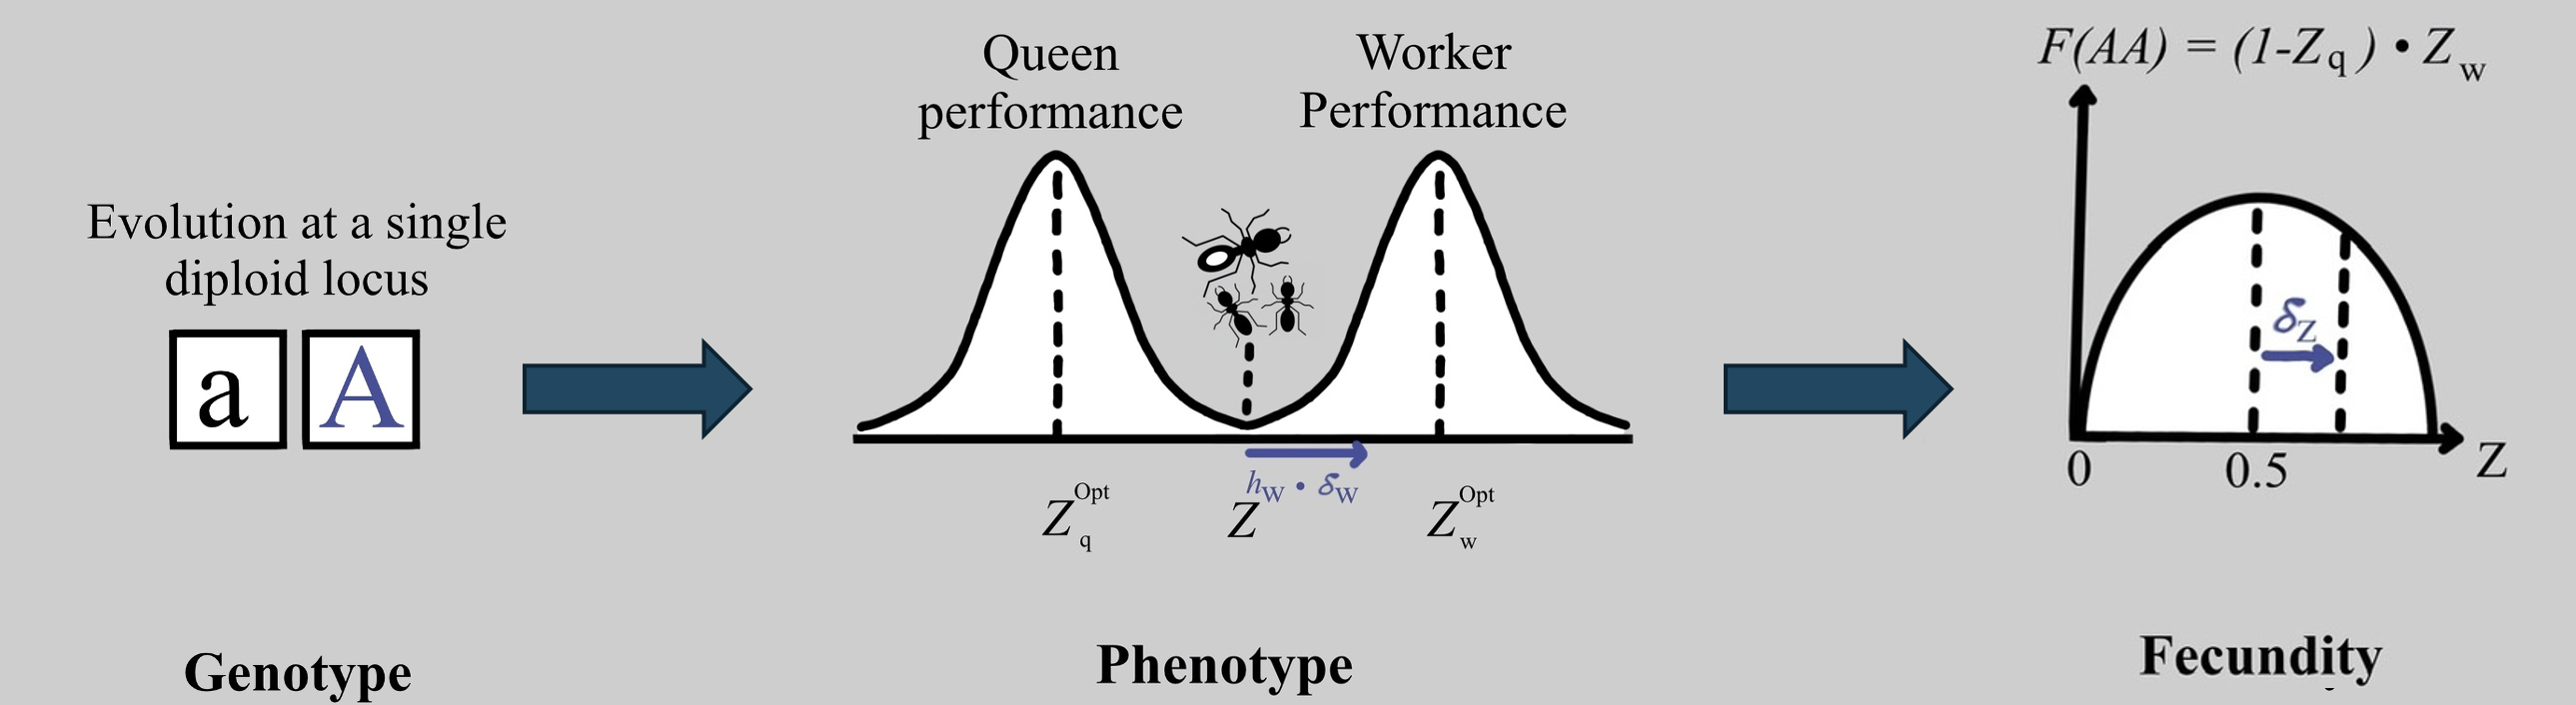
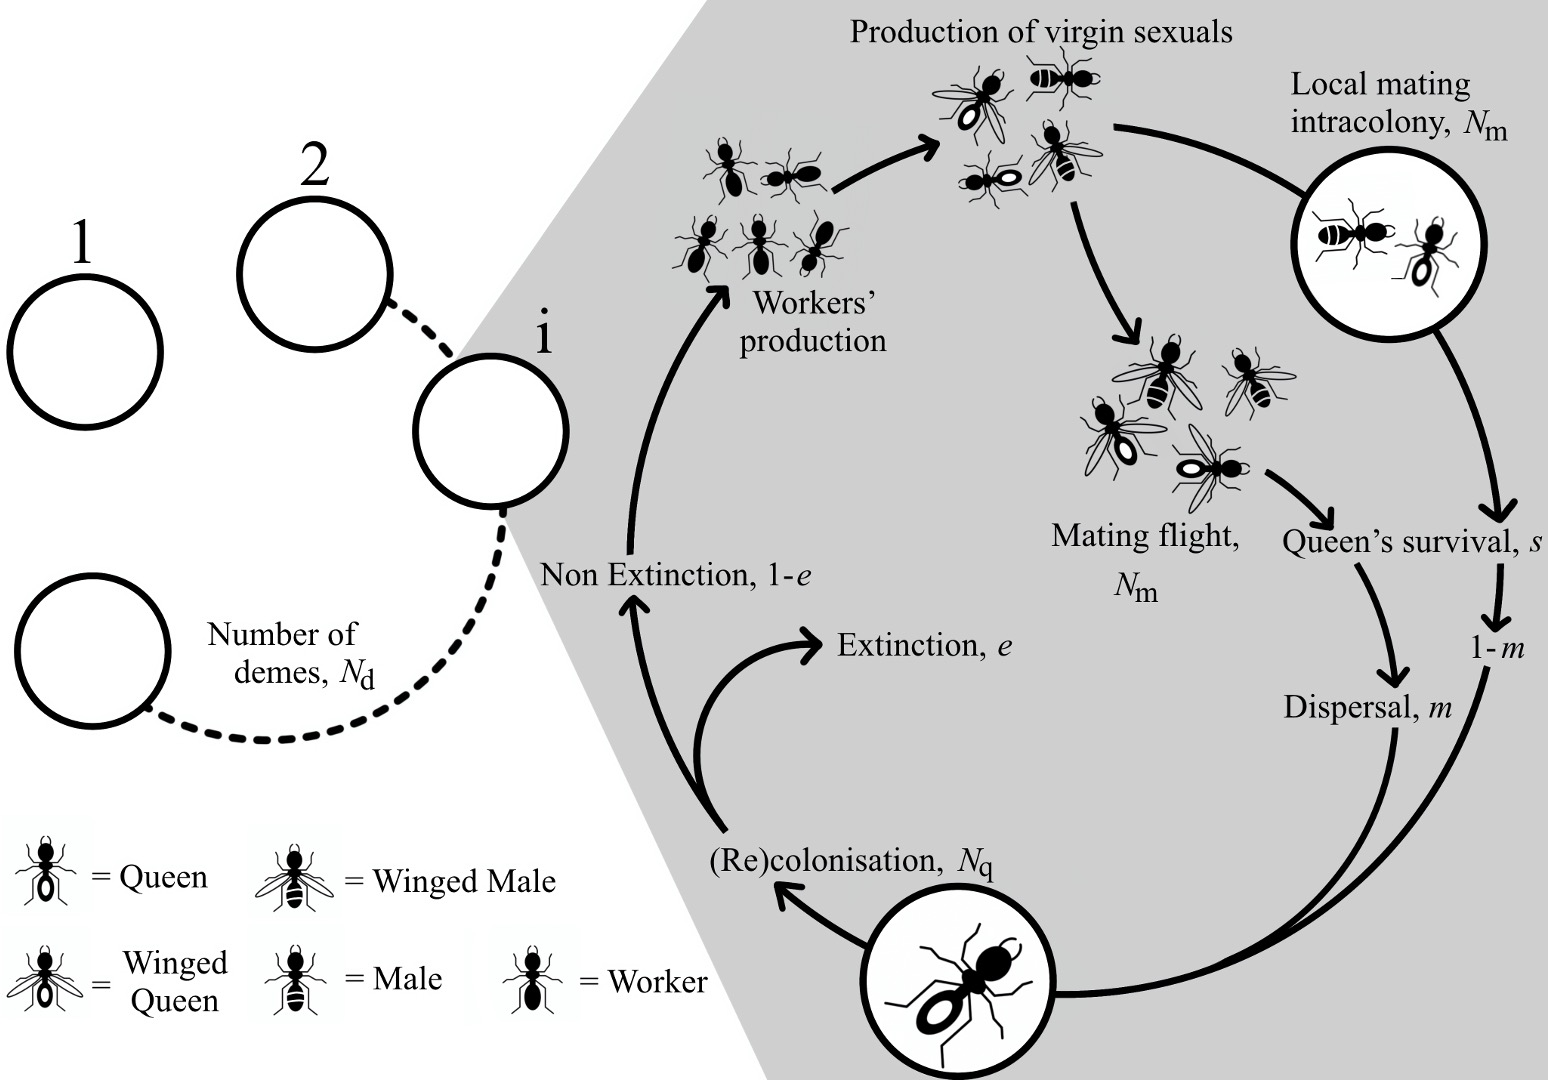

In [5]:
### --- Data Generation Using our Custom Data Generator --- ###
# error_or_not, msg = generate_dataset(n_samples=10000, reps=100, workers=4)
# print(msg)

### --- Data Loading (Adaptive for Local or Colab) --- ###
if IN_COLAB:
    print('Running in Google Colab: Fetching dataset from GitHub...')
    # Use the raw GitHub URL so Colab can download/read it directly without cloning.
    csv_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/ant_simple_model_dataset.csv'
    df = pd.read_csv(csv_url, index_col = 0)
else:
    print('Running locally: Reading dataset from local folder...')
    # Reads from your local directory where the script is saved.
    df = pd.read_csv('ant_simple_model_dataset.csv', index_col = 0)

### --- Data Cleaning --- ###
# Remove everything that is neither an explanatory feature nor the response variable.
df = df.drop(columns = ['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'])

### --- Response Variable and Features --- ###
# Separate the features from the response variable.
params_cols = ['s', 'e', 'm', 'zw', 'zq', 'dw', 'dq', 'sw', 'sq', 'Nq', 'Nm'] # All the features.
result_cols = ['frac_polymorphic'] # The response variable.

Running locally: Reading dataset from local folder...


A first look at the data confirms the structure described in Section 2. Note that `zw` equals `zq` and `sw` equals `sq` in every row: this is by design of the simulation, and we will remove these duplicates later.

In [51]:
### --- Data Display --- ###
df.head(5) # Display head of the data.

,s,e,m,zw,zq,dw,dq,sw,sq,Nq,Nm,frac_polymorphic
sample_id,,,,,,,,,,,,
0,0.357718,0.230921,0.483966,0.314324,0.314324,0.806838,0.825209,0.065894,0.065894,8,2,0.00
3,0.048572,0.359939,0.239023,0.591418,0.591418,0.944899,0.173094,0.079700,0.079700,1,3,0.00
1,0.892589,0.479211,0.830789,0.885811,0.885811,0.740353,0.034923,-0.012227,-0.012227,3,7,0.00
5,0.072650,0.630431,0.530054,0.282026,0.282026,0.443350,0.346804,0.040918,0.040918,7,9,0.00
4,0.475356,0.660237,0.224082,0.257872,0.257872,0.115671,0.831151,-0.058153,-0.058153,3,9,0.26


## **4. Exploratory Data Analysis**

Before choosing a model, we look at the data to decide **how it should be processed**.

### **4.1 Distribution of the Response Variable**

We begin with a histogram of `frac_polymorphic`. For each parameter set, this variable is the fraction of replicates (out of 100) in which polymorphism was maintained.

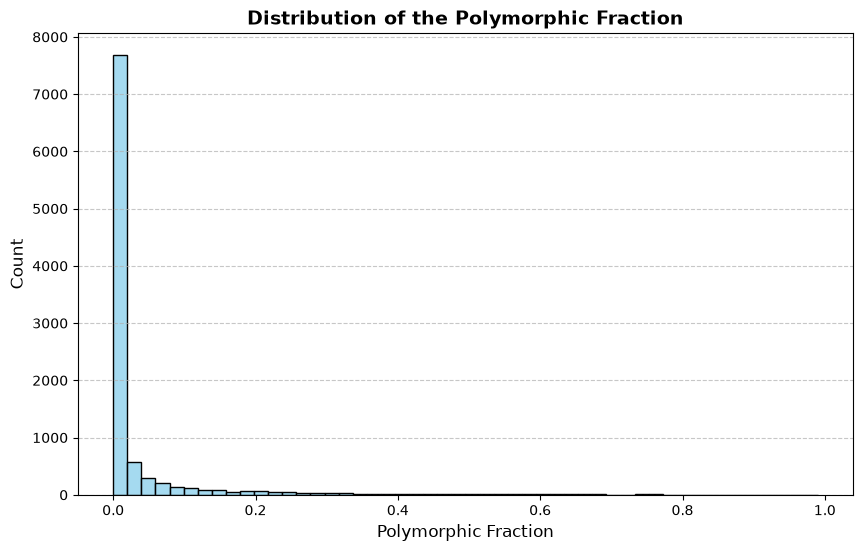

In [52]:
### --- Distribution of the Polymorphic Fraction --- ###
plt.figure(figsize = (10, 6)) # Set figure dimensions.
sns.histplot(df['frac_polymorphic'], bins = 50, color = 'skyblue') # Plots the histogram.

# Add labels, title and a horizontal dashed lines for clarity.
plt.title('Distribution of the Polymorphic Fraction', fontsize = 14, fontweight = 'bold' )
plt.xlabel('Polymorphic Fraction', fontsize = 12)
plt.ylabel('Count', fontsize = 12)
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)

# Displays plot.
plt.show()

The distribution is the classical **zero-inflated** shape: a very large spike at 0, and the remaining values spread over the rest of the range. In most parameter sets, the allele is lost or fixed in every single replicate, and only some parameter sets let polymorphism survive.

### **4.2 Classification or Regression?**

Before seeing this distribution, the problem could be framed in two valid ways. Both make biological sense, but they answer slightly different questions:

| Framing | Question answered | Cost |
|---|---|---|
| **Regression** on `frac_polymorphic` | *How much* polymorphism do we expect? | Hard to fit on such a skewed variable. |
| **Binary classification** (polymorphic or not) | *Whether* polymorphism is maintained for a given parameter set. | Loses the information on how frequent polymorphism is. |

Because the data is so skewed, a regression model would concentrate on the many zeros and would systematically under-predict polymorphism. The better option is therefore a **binary classification**, after balancing the dataset:

- **0**: non polymorphic
- **1**: polymorphic

Biologically, the main interest is whether polymorphism is maintained at all, so giving up the quantification of its frequency is an acceptable trade-off. If quantification becomes relevant later, the problem can be extended into a **hurdle model**, which splits the question into two consecutive models: a classifier that decides *whether* polymorphism occurs (this notebook), followed by a regressor trained only on the polymorphic parameter sets that estimates *how frequent* it is.

### **4.3 Class Balance**

Since we start with classification, we need to know how many parameter sets actually show some polymorphism. The bar plot below contrasts the null values (non polymorphic) with the non null values (polymorphic). A sample is called polymorphic as soon as at least one replicate kept the allele (`polymorph_threshold = 0.0`).

> **Takeaway.** There are roughly **2.5 times more non polymorphic than polymorphic** parameter sets. Training on such unbalanced data would bias the models towards predicting "non polymorphic". We will therefore remove part of the non polymorphic fraction. Before doing so, we record the current feature distributions to make sure that this reduction does not distort them.

### **4.4 Feature Distributions**

The figure below shows the distribution of each feature, separately for polymorphic and non polymorphic samples, **before** any reduction. As each parameter was drawn uniformly within its range, any visible difference between the two histograms points to a feature that influences polymorphism. These distributions must also remain unchanged once part of the data has been dropped.

In [53]:
### --- Plotting Using the Helper plot_feature_distr --- ###
plot_feature_distr(df, params_cols)

KeyboardInterrupt: 

### **4.5 Correlation Between Features**

The correlation matrix below includes all the features and the response variable. We want to **avoid strongly correlated features**, because they make models harder to interpret and make feature-importance measures unreliable. Some correlations are known in advance from the way the simulation is built.

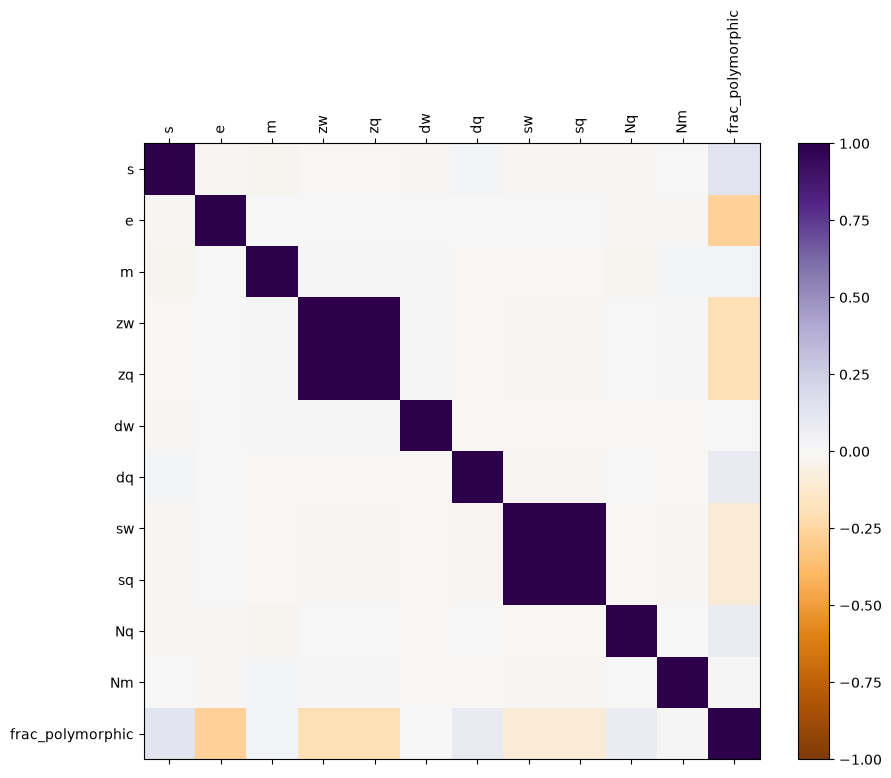

In [ ]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df)

> **Takeaway.** The only strongly correlated pairs are **`zq`/`zw`** and **`sq`/`sw`**, which are identical by design of the simulation. We will keep one variable from each pair. The feature distributions will be compared again once the reduction has been done.

## **5. Data Preparation**

### **5.1 Balancing the Classes and Removing Redundant Features**

Two operations are applied at once:

1. **Undersampling.** We keep all polymorphic parameter sets and draw, without replacement, the same number of non polymorphic ones.
2. **Dropping duplicated features.** We remove `zw` and `sw`, which are identical to `zq` and `sq`.

In [ ]:
### --- Data Reduction --- ###
# Identify all the polymorphic cases.
polymorph_threshold = 0.0
polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)

# Undersample the non polymorphic cases to match the number of polymorphic ones.
df_non_poly_thin = df[~polymorph_samples].sample(n = polymorph_samples.sum().item(), random_state = random_seed)
df_thin = pd.concat([df[polymorph_samples], df_non_poly_thin])

# Remove the redundant features (zw = zq and sw = sq by design of the simulation).
df_thin = df_thin.drop(columns = ['zw', 'sw'])
params_cols.remove('zw')
params_cols.remove('sw')

### **5.2 Checking the Reduced Data**

We now check that the reduction did what it should: balanced classes, no strongly correlated features, and feature distributions that are unchanged. The summary statistics show that **5,620 samples** remain, i.e. 2,810 polymorphic and 2,810 non polymorphic parameter sets.

In [ ]:
### --- Displaying the Statistics of the New Data Frame --- ###
df_thin.describe().head(3)

,s,e,m,zq,dw,dq,sq,Nq,Nm,frac_polymorphic
count,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000
mean,0.519169,0.458874,0.499033,0.458262,0.500111,0.498599,-0.003329,5.598932,10.531139,0.062496
std,0.290777,0.284664,0.289842,0.279189,0.288583,0.292536,0.055124,2.844990,5.761122,0.136305


**Feature distributions.** Compare with Section 4.4. The two empty panels correspond to the two features that were dropped.

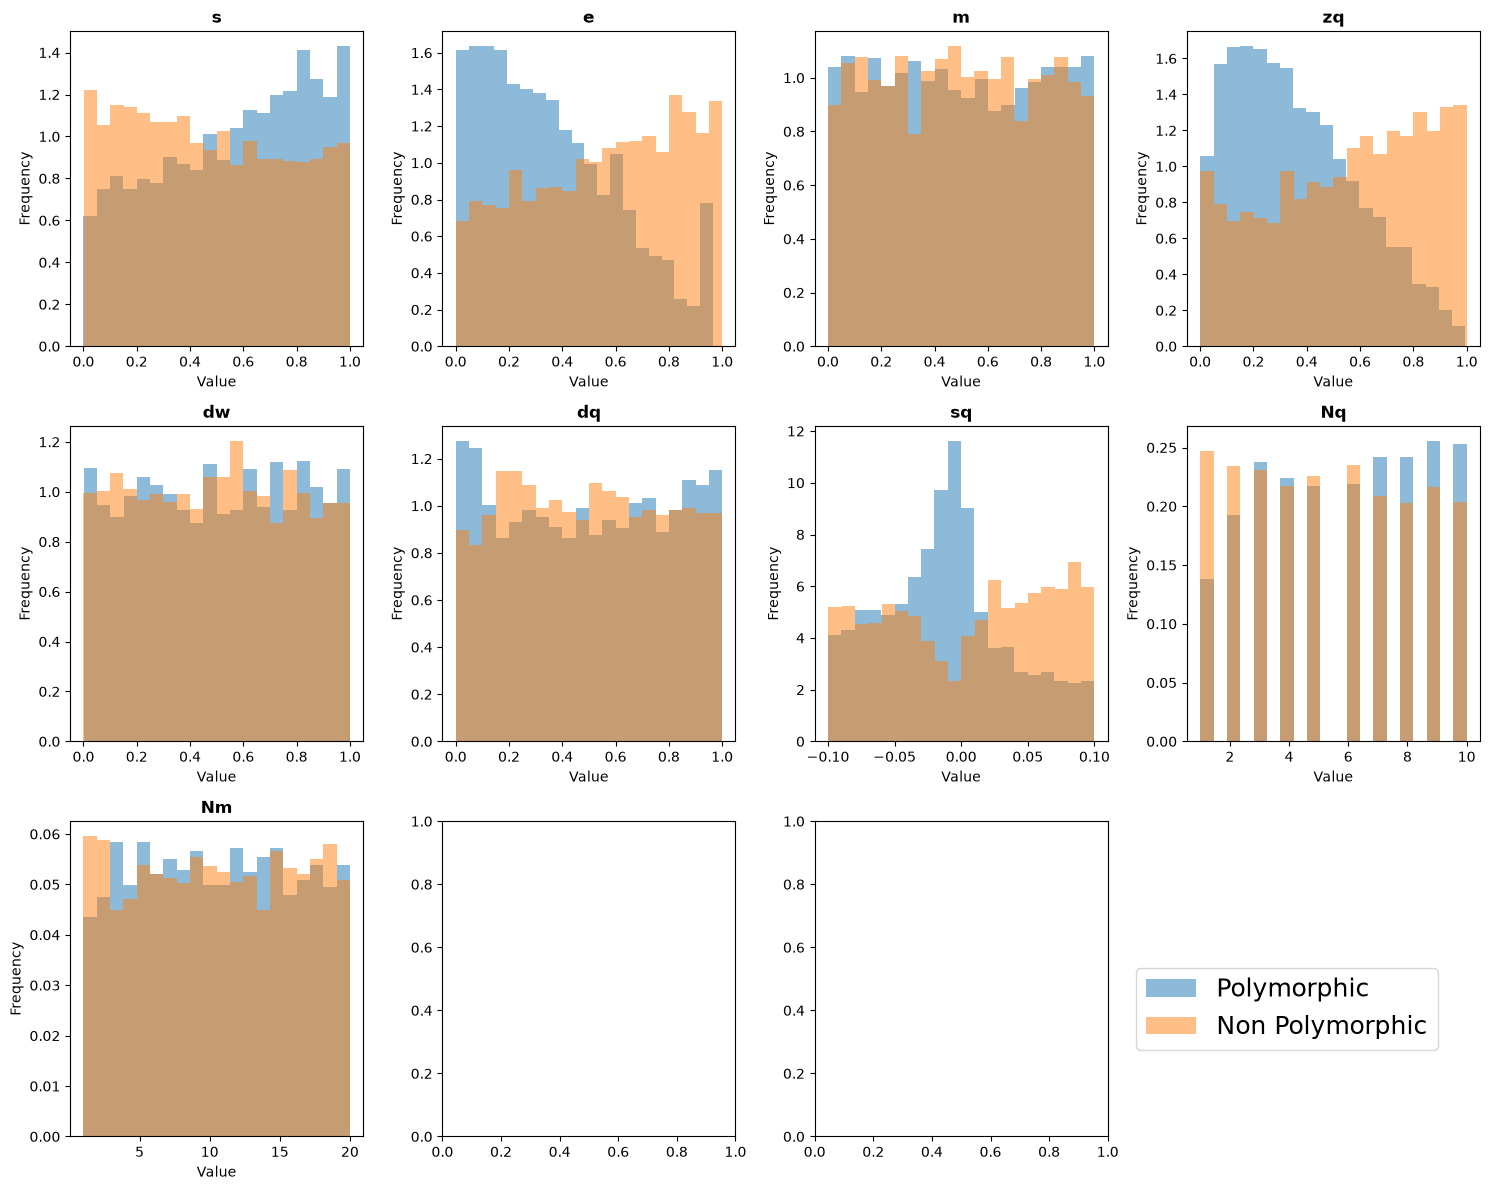

In [ ]:
### --- Plotting Using the Helper plot_feature_distr  --- ###
plot_feature_distr(df_thin, params_cols)

> **Takeaway.** The distributions are almost identical to the ones before the reduction, so the undersampling did not introduce any visible bias in the features.

**Correlation matrix.**

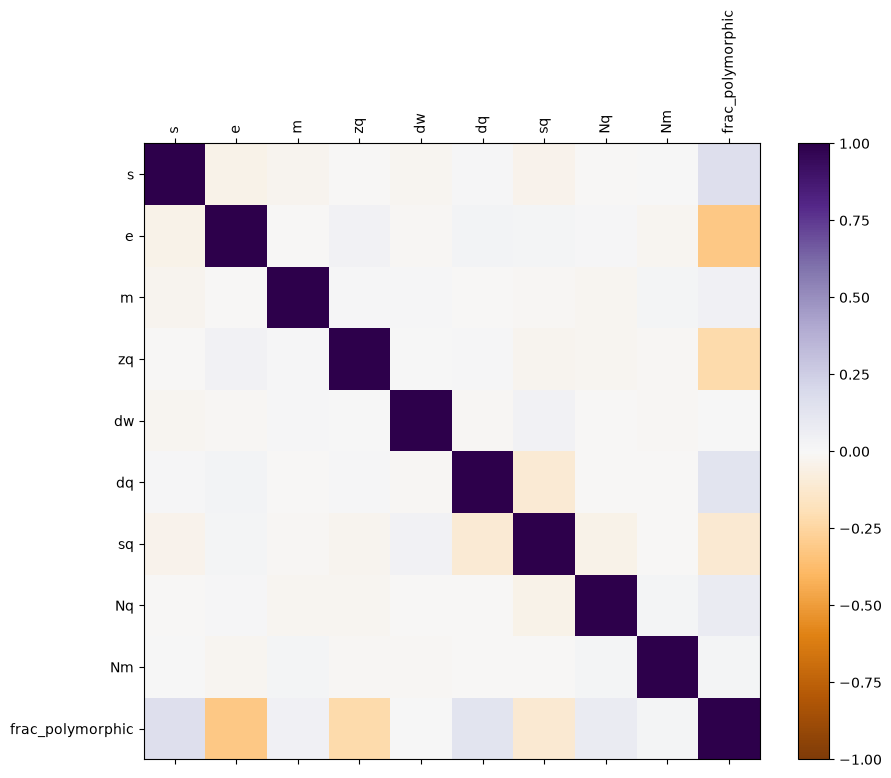

In [ ]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df_thin)

> **Takeaway.** No pair of features is strongly correlated any more.

**Class balance.**

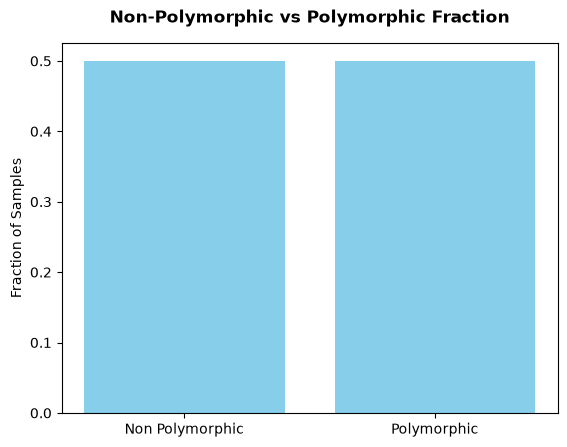

In [ ]:
### --- Polymorphic Versus Non Polymorphic Barplot --- ###
barplot_polymorphic_or_not(df_thin, polymorph_threshold = 0.0)

> **Takeaway.** The two classes now have the same size, so a classifier that guesses at random would reach about 50% accuracy. This is the baseline against which every model is compared.

### **5.3 Binary Response Variable**

The last step is to turn the continuous `frac_polymorphic` into the binary response **`polymorphic`**:

- **0**: non polymorphic (`frac_polymorphic = 0`)
- **1**: polymorphic (`frac_polymorphic > 0`)

In [ ]:
### --- Binary Response Variable for Classification --- ###
# Add the binary response `polymorphic`: 1 if at least one replicate maintained the allele, 0 otherwise.
df_thin['polymorphic'] = (df_thin['frac_polymorphic'] > polymorph_threshold).astype(int)

# Remove the continuous response and update the response variable list.
df_thin = df_thin.drop(columns = ['frac_polymorphic'])
result_cols = ['polymorphic']

# Display the balanced data set, ready to be preprocessed.
df_thin.head(5)

,s,e,m,zq,dw,dq,sq,Nq,Nm,polymorphic
sample_id,,,,,,,,,,
4,0.475356,0.660237,0.224082,0.257872,0.115671,0.831151,-0.058153,3,9,1
6,0.950576,0.340998,0.824687,0.061601,0.879456,0.219170,0.038176,8,2,1
7,0.365080,0.745140,0.400069,0.189242,0.495235,0.494838,-0.042692,7,5,1
8,0.470395,0.663667,0.124523,0.064909,0.544222,0.424700,0.047439,4,18,1
19,0.968545,0.105871,0.410403,0.127432,0.333015,0.392471,0.060766,6,10,1


### **5.4 Train / Test Split**

The 5,620 samples are split as follows:

| Set | Share | Samples | Role |
|---|---|---|---|
| **Train** | 90% | 5,058 | Fit the models and tune the hyperparameters by cross-validation. |
| **Validation** | 0% | none | Replaced by **cross-validation** inside the training set. |
| **Test** | 10% | 562 | Used **once** per model, for the final evaluation. |

In [ ]:
### --- Features / Response Separation and Train-Test Split --- ###
X = df_thin[params_cols]   # Features.
y = df_thin[result_cols]   # Response variable.

# 90% train / 10% test. There is no separate validation set: cross-validation is used inside the training set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1, random_state = random_seed)

### **5.5 Preprocessing**

The table below lists the nine features that remain and how each of them is handled.

| Feature | Meaning | Range | Transformation |
|---|---|---|---|
| `Nq` | Number of queens per colony | 1 to 10 | **One-hot encoding** (categorical) |
| `Nm` | Number of reproductive males | 1 to 20 | **One-hot encoding** (categorical) |
| `s` | Survival rate | 0.0 to 1.0 | None |
| `e` | Extinction rate | 0.0 to 1.0 | None |
| `m` | Migration rate | 0.0 to 1.0 | None |
| `dq` | Dominance in queens | 0.0 to 1.0 | None |
| `dw` | Dominance in workers | 0.0 to 1.0 | None |
| `zq` (= `zw`) | Current phenotype of the castes: 0 is the workers' optimum, 1 the queens' optimum | 0.0 to 1.0 | None |
| `sq` (= `sw`) | Allele effect: -0.1 favours workers, +0.1 favours queens | -0.1 to 0.1 | **Min-max scaling** to [0, 1] |

Two points are worth noting:

- The transformer is **fitted on the training set only** and then applied to the test set, so that no information from the test set leaks into the preprocessing.
- After encoding, the data has **37 columns**: 10 for `Nq`, 20 for `Nm`, and the 7 remaining features.

> **Takeaway.** The data is now balanced, free of redundant features and numerically encoded. It is ready for machine learning.

In [ ]:
### --- Data Preprocessing --- ###
scale_cols = ['sq']        # Column rescaled to [0, 1].
cat_cols = ['Nq', 'Nm']    # Columns encoded as categorical variables.

# Build the column transformer; all the remaining columns are passed through unchanged.
ct = ColumnTransformer(
    [('one_hot', OneHotEncoder(), cat_cols),
     ('scaled', MinMaxScaler(feature_range = (0, 1)), scale_cols)],
    remainder = 'passthrough')

# Fit on the training set only, then apply the same transformation to the test set.
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

## **6. Modelling Strategy**

We train five classifiers in order of increasing flexibility, which also means decreasing interpretability. The goal is not only to reach a high accuracy but also to see **how much accuracy each additional level of complexity buys**, and what we lose in biological insight in exchange.

| Section | Model | Main strength |
|---|---|---|
| 7 | Logistic regression | Simple, linear baseline |
| 8 | Decision tree | Fully readable "white-box" rules |
| 9 | Random forest | Ensemble of trees, much more accurate |
| 10 | XGBoost | Gradient-boosted trees, usually the most accurate on tabular data |
| 12 | Multilayer perceptron | Neural network, can capture complex non-linearities |

**Common protocol.** All models are evaluated in the same way:

- **Hyperparameter tuning** with `RandomizedSearchCV` on the training set, using k-fold cross-validation and **accuracy** as the scoring metric. Tuned tree-based models and neural networks are prone to overfitting, so the search spaces were restricted to limit model complexity.
- **Three accuracies** are reported: on the full training set, from cross-validation, and on the held-out test set. A large gap between training and test accuracy is a sign of overfitting.
- A **confusion matrix**, which shows the share of true negatives (TN), false positives (FP), false negatives (FN) and true positives (TP). The diagonal holds the correct predictions.
- A **ROC curve**, which plots the true positive rate against the false positive rate over all decision thresholds. The **AUC** summarises it: 0.5 is chance level and 1.0 is a perfect classifier.

## **7. Logistic Regression**

We start simple with a **logistic regression**. It is a linear model: it can only capture relationships in which each feature pushes the probability of polymorphism steadily in one direction, so it makes a good baseline.

Its only tunable hyperparameter is `C`, the inverse of the regularisation strength (a larger `C` means weaker regularisation). We search over four values with 5-fold cross-validation. Since the search space contains only four candidates, the randomised search effectively tests all of them.

In [ ]:
### --- Best Logistic Regression Model --- ###

### --- Hyperparameter Tuning --- ###
# Define the parameter grid (only param C).
hyp_param = dict(C= [0.001, 0.01, 0.1, 1.0])

# Initialize the base model.
log_reg_model = LogisticRegression(random_state = random_seed, max_iter = 1000)

# Let's randomly search the hyperparameter space.
grid_search = RandomizedSearchCV(
    estimator=log_reg_model, 
    param_distributions=hyp_param, 
    cv=5,                       # cv=5 means 5-fold cross-validation on your training data.
    scoring='accuracy'          # scoring='accuracy' optimizes for accuracy.
)

# Fit the random search.
search = grid_search.fit(X_train, y_train)
best_C = grid_search.best_params_['C']           # Best C hyperparameter.
best_log_reg_model = grid_search.best_estimator_ # Object containing the best logistic 
                                                 # regression model.

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_log_reg_model.predict(X_train)) # Whole training set accuracy.
CVval_acc = search.best_score_                                           # Best cross validation accuracy.
test_acc = accuracy_score(y_test, best_log_reg_model.predict(X_test))    # Testing set accuracy.

print(f'--- Set Accuracies for LR (Best C: {best_C}) ---')
print(f'Train Accuracy:                      {train_acc:.4f}')
print(f'Cross-Validation Accuracy:           {CVval_acc:.4f}')
print(f'Test Accuracy:                       {test_acc:.4f}\n')

--- Set Accuracies for LR (Best C: 0.1) ---
Train Accuracy:                      0.7408
Cross-Validation Accuracy:           0.7372
Test Accuracy:                       0.7456



The best value is `C = 0.1`. The three accuracies are very close to each other (about 74% to 75%), so the model **does not overfit**. It is also clearly better than the 50% baseline. The small gap between the training and test accuracies shows that the limit comes from the model itself, which is too simple, rather than from the data.

### **7.1 Confusion Matrix**

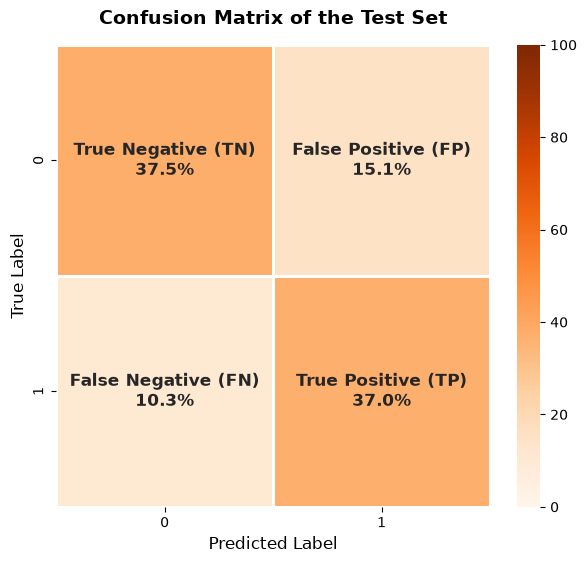

In [ ]:
### --- Confusion Matrix for Logistic Regression --- ###
plot_confusion_matrix(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

The model is right **a bit less than three times out of four**. A random guess would be right only one time out of two, but there is clearly room for improvement.

### **7.2 ROC Curve**

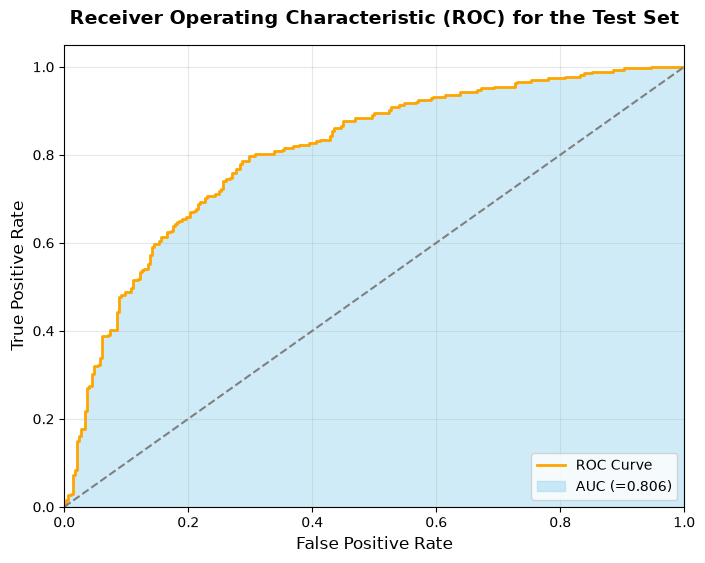

In [ ]:
### --- ROC Curve for Logistic Regression --- ###
plot_roc(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

> **Takeaway.** The logistic regression reaches a **test accuracy of about 75%**, a decent first result. As it cannot represent interactions or thresholds, the remaining error probably comes from **non-linear relationships** between the parameters and polymorphism. We explore this with a decision tree.

## **8. Decision Tree**

A **decision tree** repeatedly splits the data with simple threshold rules on one feature at a time, so it can capture non-linear effects and interactions. Trees tend to **overfit**: a default, unrestricted tree was tried first and, as expected, memorised the training set.

To limit this, we combined two strategies:

- A **randomised search with 10-fold cross-validation** over the main complexity hyperparameters (depth, minimum leaf size, number of features per split, split criterion). The search ranges were narrowed by trial and error to the zone that reduces overfitting.
- **Cost-complexity pruning** with `ccp_alpha = 0.006`, which removes branches that add little accuracy. This makes the tree much easier to read without any real loss of accuracy.

In [ ]:
### --- Best Decision Tree --- ###

### --- Hyperparameter Tuning --- ###
# Here is the hyperparameter space we found 
# was appropriate to reduce overfitting.
hyp_params = dict(
    max_depth = range(1, 20),
    min_samples_leaf = range(5, 20),
    max_features = [None, 'sqrt', 'log2'],
    criterion = ['gini', 'entropy']
)

# Let's randomly search the hyperparameter space.
dt_opt = RandomizedSearchCV(
    DecisionTreeClassifier(random_state = random_seed, ccp_alpha = 0.006), 
    hyp_params, 
    random_state = 0, 
    cv = 10, 
    scoring = 'accuracy'
)

# Fit the random search.
print("------ Running Randomized Search for Decision Tree ------")
search = dt_opt.fit(X_train, y_train['polymorphic'])
best_model_dt = search.best_estimator_                  # Best model.
best_dt_params = search.best_params_                    # Best hyperparameter set.
print(f"\nBest Hyperparameters Found: {best_dt_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_model_dt.predict(X_train)) # Whole training set accuracy.
CVval_acc = search.best_score_                                      # Best cross validation accuracy.
test_acc = accuracy_score(y_test, best_model_dt.predict(X_test))    # Testing set accuracy.

print('------ Set Accuracies for DT ------')
print(f'Train Accuracy:              {train_acc:.4f}')
print(f'Cross-validation Accuracy:   {CVval_acc:.4f}')
print(f'Test Accuracy:               {test_acc:.4f}\n')

------ Running Randomized Search for Decision Tree ------

Best Hyperparameters Found: {'min_samples_leaf': 6, 'max_features': None, 'max_depth': 9, 'criterion': 'entropy'}

------ Set Accuracies for DT ------
Train Accuracy:              0.8064
Cross-validation Accuracy:   0.7859
Test Accuracy:               0.7972



The best tree uses the entropy criterion, a maximum depth of 9 and at least 6 samples per leaf. The training, cross-validation and test accuracies are all within about two percentage points of each other (around 80%), which shows that overfitting has been kept under control. The test accuracy is about **5 percents higher** than the logistic regression.

### **8.1 The Tree Itself**

Each box below shows a rule, the number of samples, the class distribution and the majority class (colour). Reading the tree from the root to a leaf gives a set of conditions under which polymorphism is, or is not, predicted.

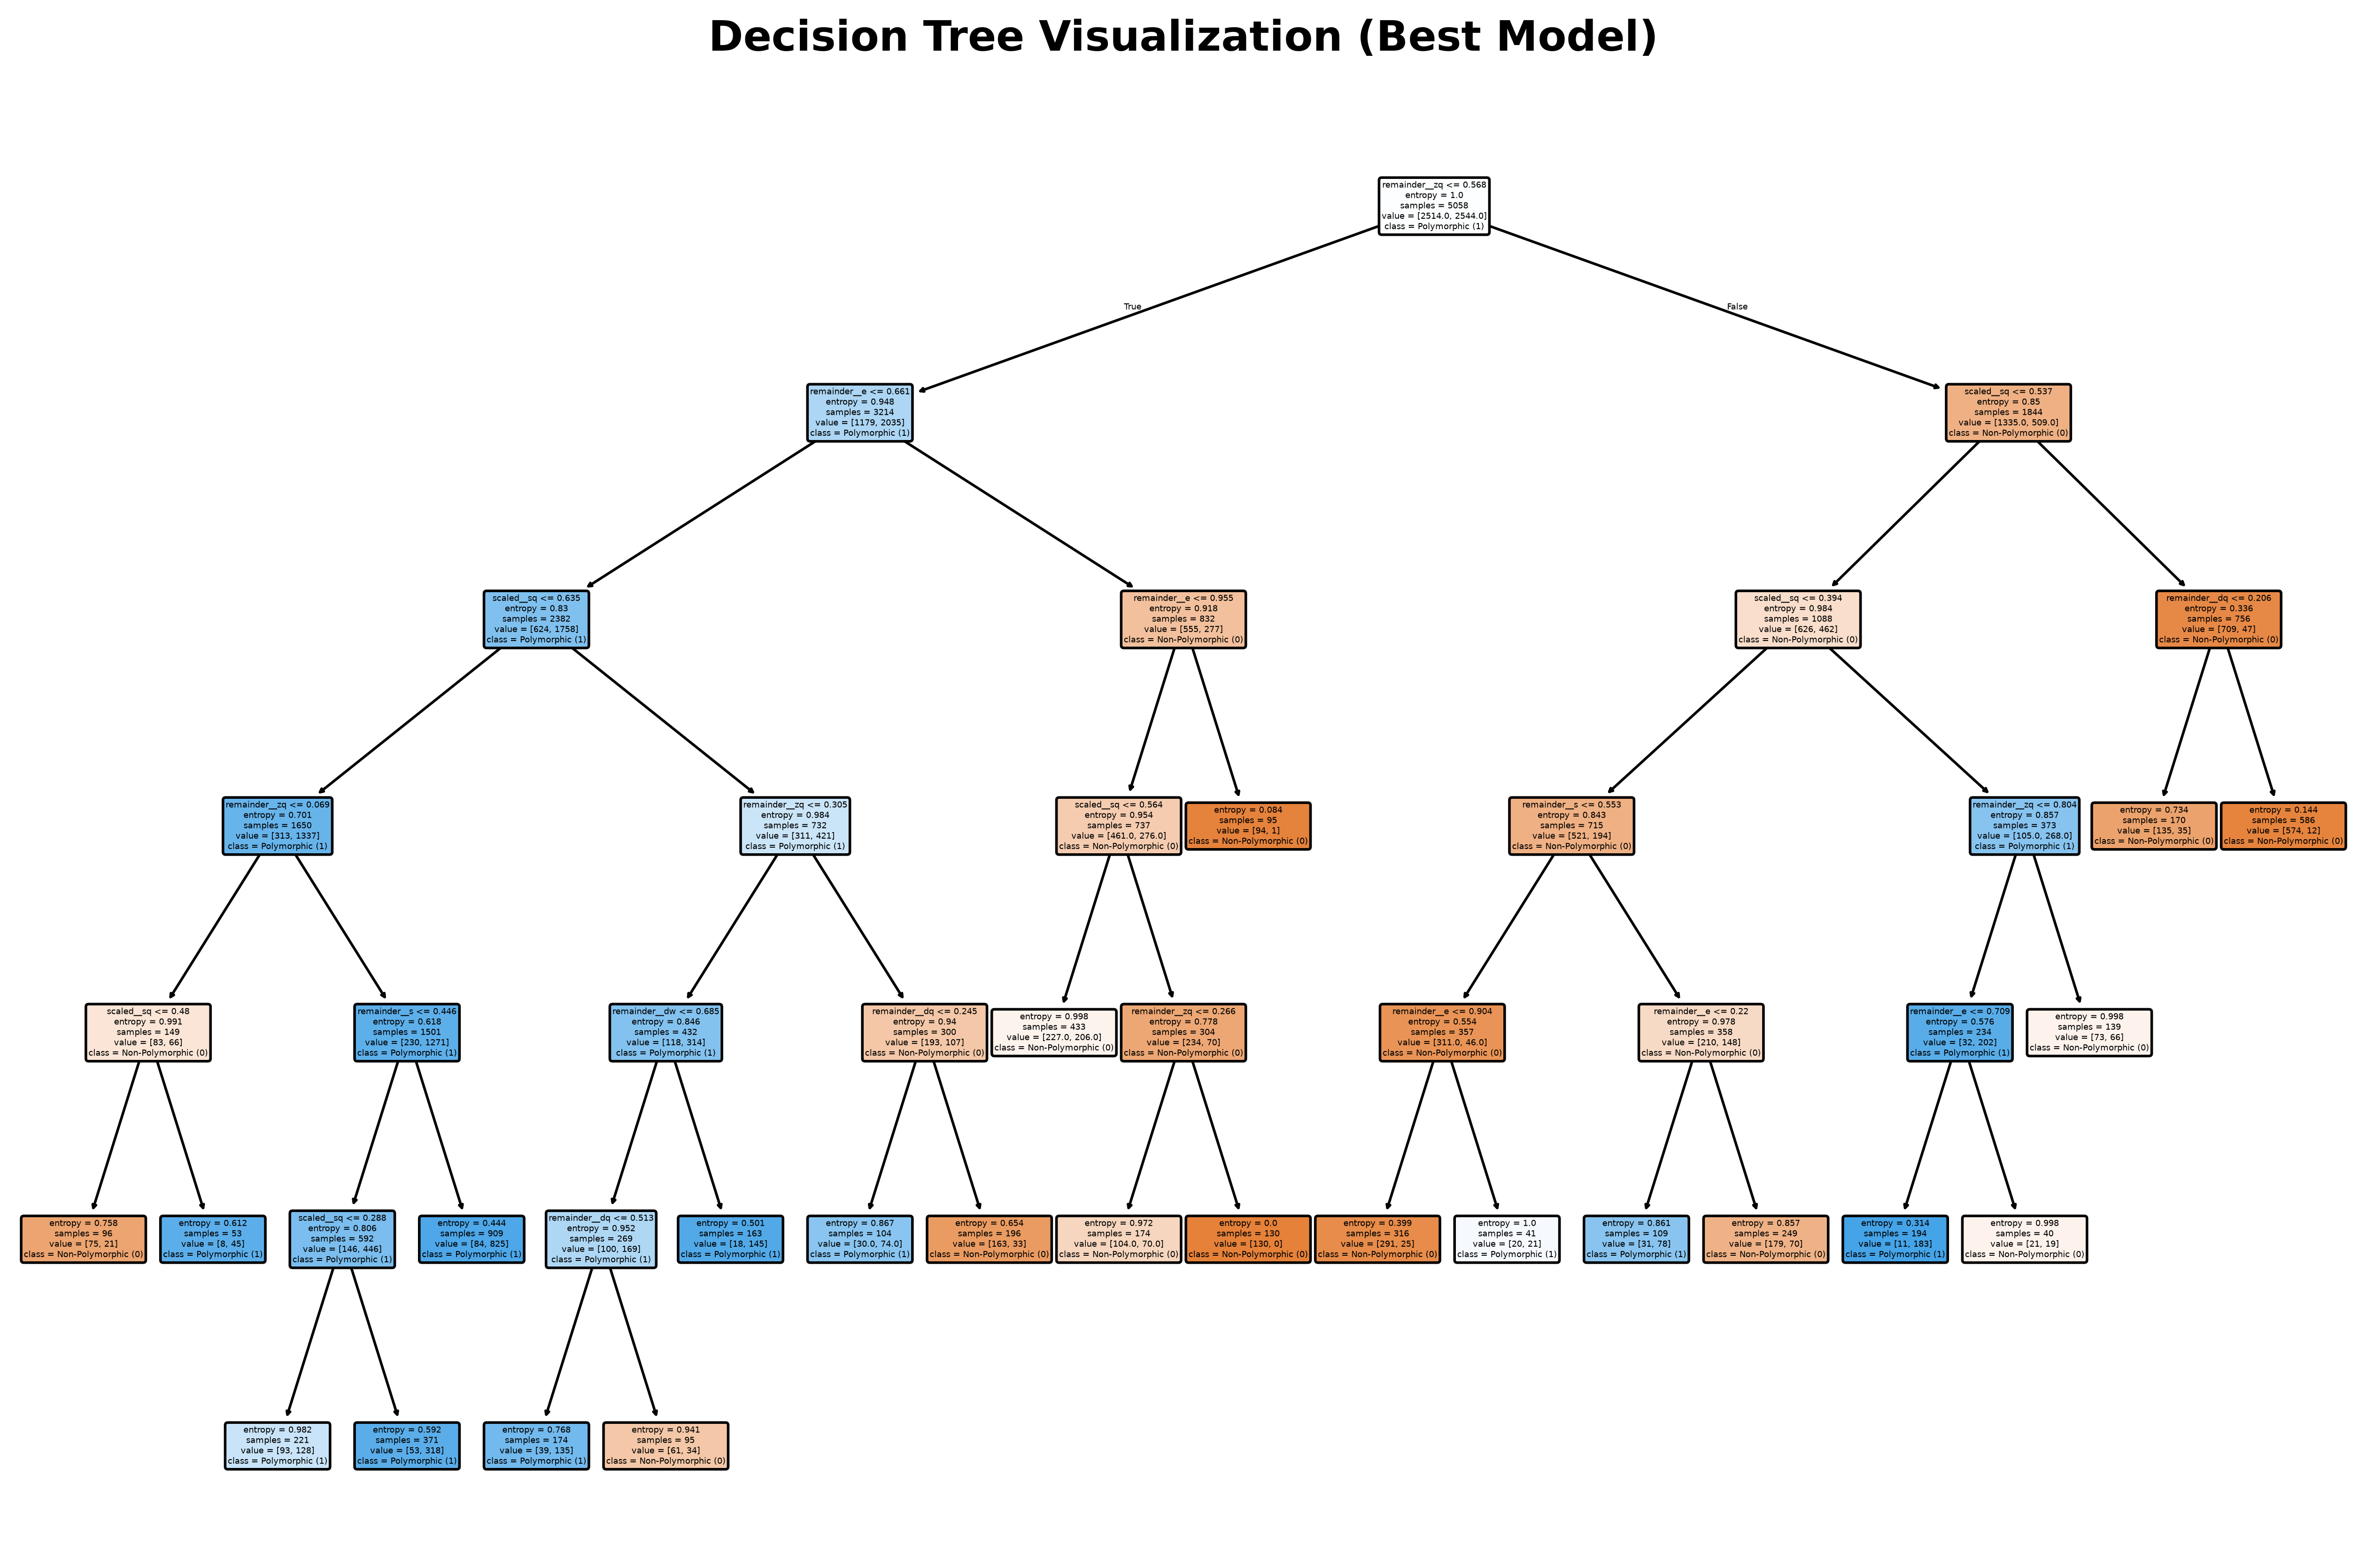

In [ ]:
### --- Plot the Decision Tree --- ###
encoded_feature_names = ct.get_feature_names_out() # Get the feature names after the 
                                                   # ColumnTransformer transformation.
# Plot figures.
plt.figure(figsize = (16, 10), dpi = 400)

# Add tree in figure.
plot_tree(
    best_model_dt, 
    feature_names = encoded_feature_names, 
    class_names = ['Non-Polymorphic (0)', 'Polymorphic (1)'],
    filled = True,          # Colors nodes by majority class
    rounded = True,         # Rounds the node boxes for a clean look
)

# Display figure and title.
plt.title("Decision Tree Visualization (Best Model)", fontsize = 16, fontweight = 'bold', pad = 20)
plt.show()

We now have a compact, readable tree with a decent accuracy. This gives a **direct biological interpretation** of how the model works: we can follow which parameters are used first and which thresholds matter. We should nonetheless keep going, in order to see how much more accuracy can be gained with more complex models.

### **8.2 Confusion Matrix**

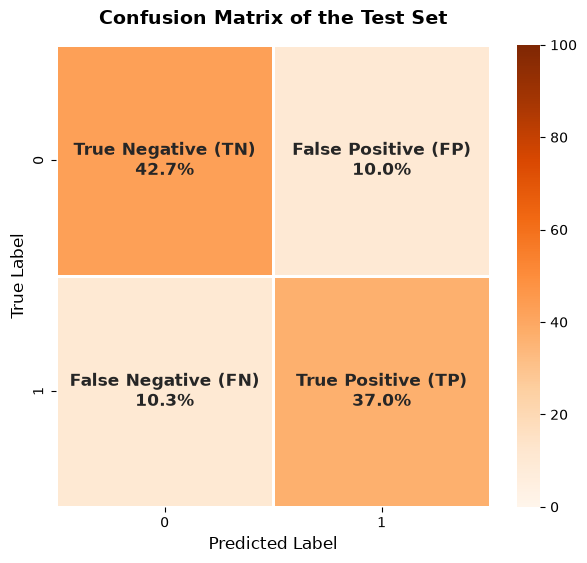

In [ ]:
### --- Confusion Matrix for Decision Tree --- ###
plot_confusion_matrix(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test")

Accuracy improved markedly: the tree classifies correctly **about four samples out of five**.

### **8.3 ROC Curve**

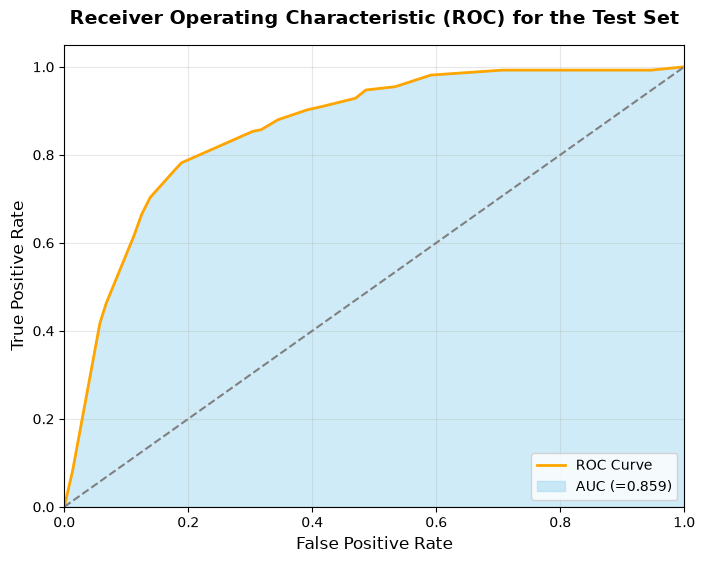

In [ ]:
### --- ROC Curve for Decision Tree--- ###
plot_roc(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test")

> **Takeaway.** The decision tree reaches a **test accuracy of about 80%**, which confirms that the relationship between the parameters and polymorphism is non-linear. It is also a **white-box model**: its rules can be read and translated into biological statements. Its accuracy can still be improved with ensembles, at the price of this readability.

## **9. Random Forest**

A **random forest** is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the data and considers only a random subset of the features at each split, and the final prediction is the **majority vote** of all the trees. Averaging many different trees reduces the variance of a single tree and usually gives a more accurate and stable model.

Random forests can overfit too (a default forest was tried and did), so the search space limits the complexity of the trees:

- **Shallow trees** (`max_depth` from 1 to 7), which stops them from memorising the data.
- **Large leaves and splits** (`min_samples_split`, `min_samples_leaf`), which prevent tiny, hyper-specific groups.
- **Feature subsampling** (`max_features`), which adds diversity between the trees.

The search uses 20 random combinations and 5-fold cross-validation.

In [ ]:
### --- Best Random Forest --- ###

### --- Hyperparameter Tuning --- ###
# Define a hyperparameter space that restricts tree complexity.
param_dist = {
    'n_estimators': [50, 100, 200, 300],           # Number of trees.
    'max_depth': range(1,8),                       # Limiting depth stops memorization.
    'min_samples_split': [3, 5, 10, 20, 50],       # Requires more samples to split a node.
    'min_samples_leaf': [2, 5, 10, 20],            # Prevents leaves from having tiny, hyper-specific groups.
    'max_features': ['sqrt', 'log2', 0.5],         # Subsets features per tree to add diversity.
    'bootstrap': [True]
}

# Let's randomly search the hyperparameter space.
rf_base = RandomForestClassifier(random_state = random_seed) # Default RF.
rf_opt = RandomizedSearchCV(
    estimator = rf_base,
    param_distributions = param_dist,
    n_iter = 20,
    cv = 5,
    scoring = 'accuracy',
    random_state = random_seed,
    n_jobs = -1 # Uses all available CPU cores.
)

# Fit the random search.
print("------ Running Randomized Search for Random Forest ------")
search = rf_opt.fit(X_train, y_train['polymorphic'])
best_rf_model = search.best_estimator_ # Best model.
best_rf_params = search.best_params_   # Best hyperparameters set.
print(f"\nBest Hyperparameters Found: {best_rf_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_rf_model.predict(X_train)) # Whole training set accuracy.
CVval_acc = search.best_score_                                      # Best cross validation accuracy.
test_acc  = accuracy_score(y_test, best_rf_model.predict(X_test))   # Testing set accuracy.

print('------ Set Accuracies for RF ------')
print(f'Train Accuracy:              {train_acc:.4f}')
print(f'Cross-validation Accuracy:   {CVval_acc:.4f}')
print(f'Test Accuracy:               {test_acc:.4f}\n')

------ Running Randomized Search for Random Forest ------

Best Hyperparameters Found: {'n_estimators': 100, 'min_samples_split': 3, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 7, 'bootstrap': True}

------ Set Accuracies for RF ------
Train Accuracy:              0.9102
Cross-validation Accuracy:   0.8527
Test Accuracy:               0.8488



The forest gains about **5 points of test accuracy** over the decision tree (from about 80% to about 85%). The cross-validation and test accuracies agree closely, which is reassuring. The training accuracy is higher (about 91%), so a moderate amount of overfitting remains, even though the search was restricted to limit it.

### **9.1 Confusion Matrix**

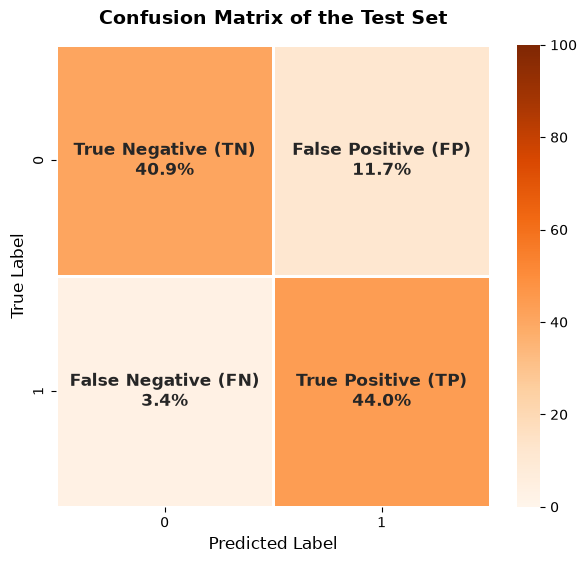

In [ ]:
### --- Confusion Matrix for Random Forest --- ###
plot_confusion_matrix(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

The model now classifies correctly about **85% of the samples**.

### **9.2 ROC Curve**

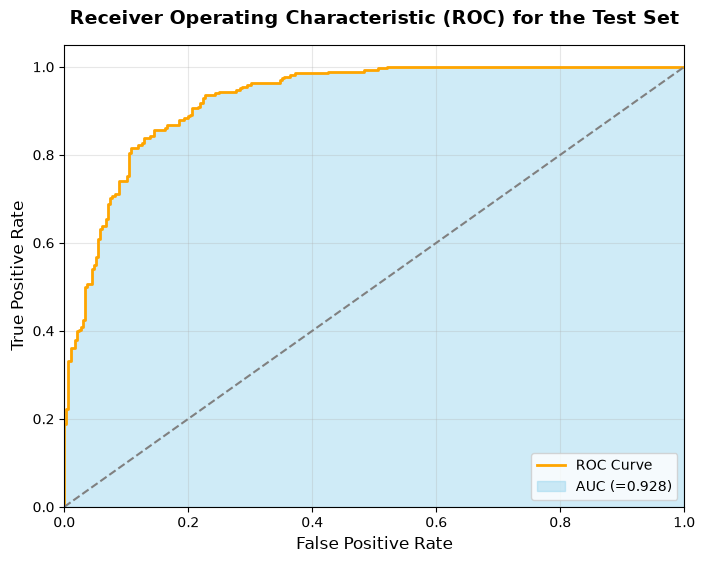

In [ ]:
### --- ROC Curve for Random Forest --- ###
plot_roc(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

The ROC curve confirms that this model is much better than the models we started with.

### **9.3 Feature Importance**

The plot below ranks the features by their contribution to the splits of the forest. It tells us **which features the model relies on** to classify. Such a plot is reliable here because the features are now almost perfectly uncorrelated (see Section 5.2).

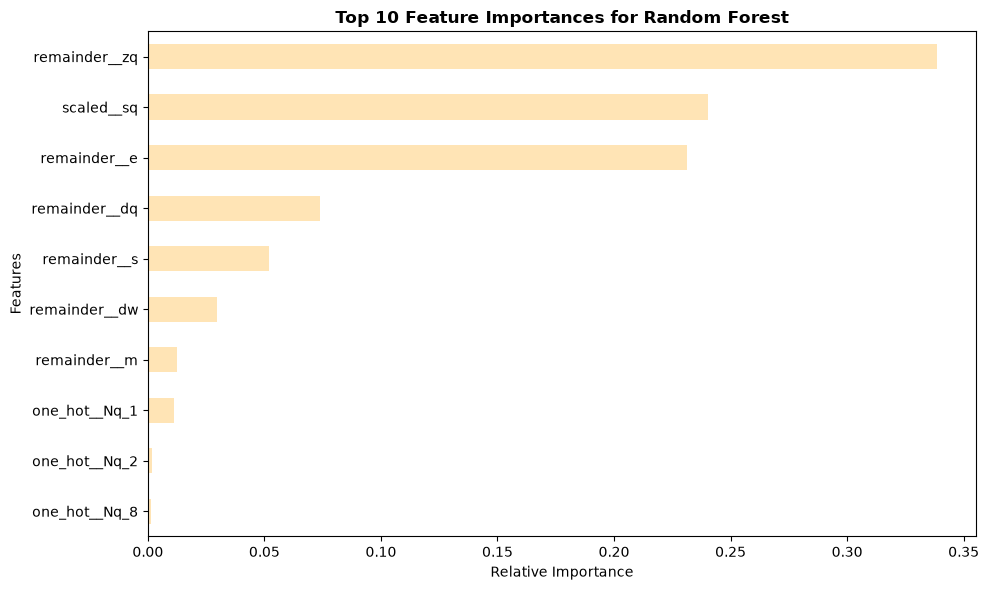

In [ ]:
### --- Feature Importance Plot for Random Forest --- ###
feat_imp_plot(preprocess = ct, model = best_rf_model, model_name = 'Random Forest')

Three features dominate: **`zq`, `sq` and `e`** together account for roughly four fifths of the total importance. They are followed by `dq`, `s` and `dw`. The number of queens and males (`Nq`, `Nm`) and the migration rate `m` matter little in this ranking.

> **Takeaway.** The random forest improves the accuracy by **about 5 percents**, but we lose part of the biological readability: the importance plot says *which* features matter, not *how* they act, nor whether they interact. Both questions come back with SHAP in Section 11.

## **10. XGBoost**

**XGBoost** (eXtreme Gradient Boosting) also builds an ensemble of trees, but in a different way from the random forest. The trees are trained **sequentially**, each one correcting the errors of the previous ones (**gradient boosting**). It often outperforms a random forest on tabular data.

Boosting overfits easily, so the search space contains several regularisation levers: a small learning rate (step-size shrinkage), subsampling of the rows and columns for every tree, a minimum child weight, and L1 (`reg_alpha`) and L2 (`reg_lambda`) penalties. The search uses 30 random combinations and 5-fold cross-validation.

In [ ]:
### --- Best eXtreme Gradient Boosting --- ###

### --- Hyperparameter Tuning --- ###
# Define the hyperparameter search space for XGBoost.
param_dist_xgb = {
    'n_estimators': [300, 500, 1000],
    'max_depth': range(1,8),                    # Depth of sequential trees.
    'learning_rate': [0.01, 0.02, 0.03],        # Step size shrinkage to prevent overfitting.
    'subsample': [0.5, 0.6, 0.7],               # Fraction of samples used per tree.
    'colsample_bytree': [0.5, 0.6, 0.7],        # Fraction of features used per tree.
    'min_child_weight': [8, 9, 10],             # Minimum sum of instance weight needed in a child.
    'reg_alpha': [0, 5],                        # L1 regularization (encourages sparsity).
    'reg_lambda': [0, 5]                        # L2 regularization (smooths weights).
}

# Let's randomly search the hyperparameter space.
xgb_base = XGBClassifier(random_state = random_seed, eval_metric = 'logloss')
xgb_opt = RandomizedSearchCV(
    estimator = xgb_base,
    param_distributions = param_dist_xgb,
    n_iter = 30,
    cv = 5,
    scoring = 'accuracy',
    random_state = random_seed,
    n_jobs = -1
)

# Fit the random search.
print("------ Running Randomized Search for XGBoost ------")
search_xgb = xgb_opt.fit(X_train, y_train['polymorphic'])
best_xgb_model = search_xgb.best_estimator_ # Best model.
best_xgb_params = search_xgb.best_params_   # Best hyperparameters set.
print(f"\nBest Hyperparameters Found: {best_xgb_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train['polymorphic'], best_xgb_model.predict(X_train)) # Whole training set accuracy.
CVval_acc = search_xgb.best_score_                                                      # Best cross validation accuracy.
test_acc  = accuracy_score(y_test['polymorphic'], best_xgb_model.predict(X_test))   # Testing set accuracy.

print('------ Set Accuracies for XGB ------')
print(f'Train Accuracy:                    {train_acc:.4f}')
print(f'Cross validation Accuracy:         {CVval_acc:.4f}')
print(f'Test Accuracy:                     {test_acc:.4f}\n')

------ Running Randomized Search for XGBoost ------

Best Hyperparameters Found: {'subsample': 0.6, 'reg_lambda': 5, 'reg_alpha': 5, 'n_estimators': 1000, 'min_child_weight': 8, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.5}

------ Set Accuracies for XGB ------
Train Accuracy:                    0.9417
Cross validation Accuracy:         0.8760
Test Accuracy:                     0.8843



In the reference run, XGBoost reached a **test accuracy of about 88%**, i.e. **4 percents better than the random forest** (training accuracy about 94%). The selected configuration is deep and strongly regularised: a learning rate of 0.03 with 1,000 trees, a maximum depth of 7, and both L1 and L2 penalties set to 5 and 0 respectively.

### **10.1 Confusion Matrix**

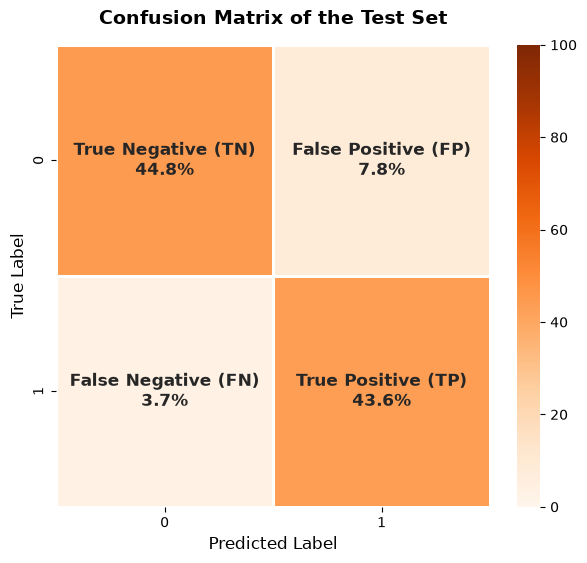

In [ ]:
### --- Confusion Matrix for XGBoost --- ###
plot_confusion_matrix(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

The model classifies correctly **nearly nine samples out of ten**.

### **10.2 ROC Curve**

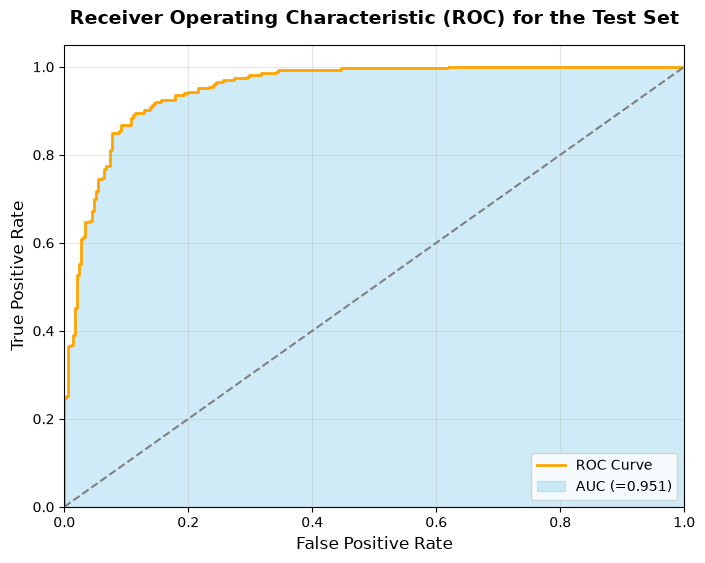

In [ ]:
### --- ROC Curve for XGBoost --- ###
plot_roc(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

The ROC curve confirms that this model is better than the random forest.

### **10.3 Feature Importance**

As for the random forest, the features are almost uncorrelated, so this ranking is reliable.

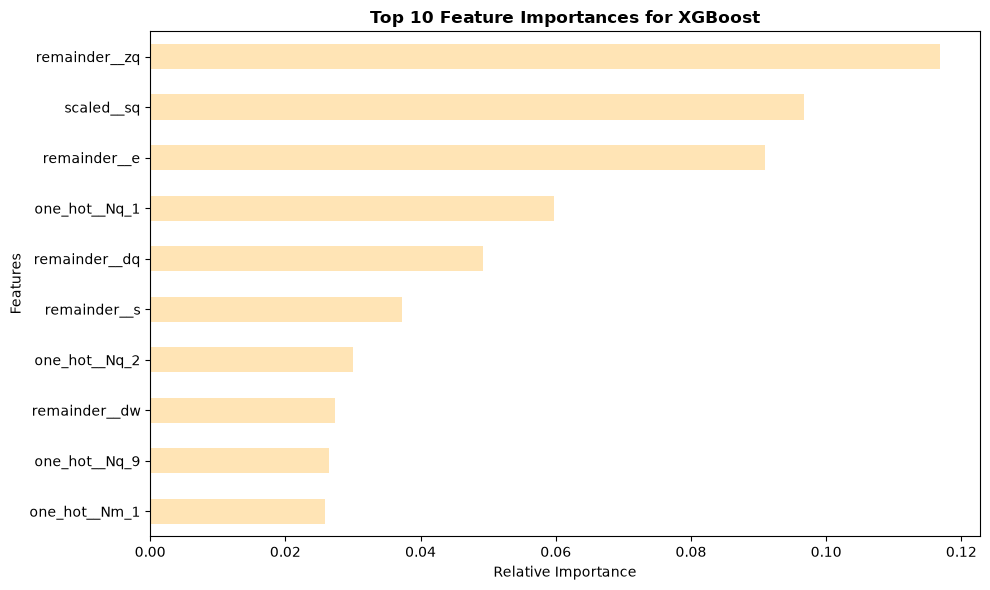

In [ ]:
### --- Feature Importance Plot for XGBoost --- ###
feat_imp_plot(preprocess = ct, model = best_xgb_model, model_name = 'XGBoost')

The ranking is similar to the one of the random forest: **`zq`, `sq` and `e`** come first. XGBoost, however, gives more weight to the number of queens: the dummy variables for **single-queen colonies (`Nq_1`)** and for two queens (`Nq_2`) rank in the top ten.

This ranking says *how much* each feature matters, but not *in which direction* or *with which partner*. SHAP answers these questions next in section 11.

## **11. Interpreting XGBoost with SHAP**

XGBoost is our most accurate model, but it is a black box. To open it, we use **SHAP** (SHapley Additive exPlanations). SHAP breaks down every individual prediction into the **contribution of each feature**, expressed in log-odds: a positive SHAP value pushes the prediction towards *polymorphic*, a negative one towards *non polymorphic*. Because SHAP values are computed per sample, they reveal what plain importance scores cannot: the **direction** of each effect and the **interactions** between features. We use `TreeExplainer`, which is exact and fast for tree ensembles.

The analysis has two stages:

- **Stage 1: global explanation.** Which features drive the predictions overall, and which pairs of features interact?
- **Stage 2: a focused question.** Do the dominance of the allele in queens (`dq`) and in workers (`dw`) interact with the sign of the allele effect (`sq`) the way theory would suggest?

### **11.1 Rebuilding Labelled Data Frames**

SHAP plots need **named columns**. The cell below repeats the split (same seed, so the **same samples** as before) and the preprocessing, then rebuilds `X_train` and `X_test` as DataFrames with clean feature names (for instance `Nq_3` instead of `one_hot__Nq_3`). It also keeps copies of the features on their **original scale** (`X_train_original`, `X_test_original`), which are used in Stage 2.

In [ ]:
### --- Preprocessed Data as Labelled DataFrames --- ###
X = df_thin[params_cols]
y = df_thin[result_cols]

# Train / test split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=random_seed
)

X_train_original = X_train.copy()
X_test_original = X_test.copy()

# Data preprocessing.
scale_cols = ['sq']
cat_cols = ['Nq', 'Nm']

ct = ColumnTransformer(
    [
        ('one_hot', OneHotEncoder(), cat_cols),
        ('scaled', MinMaxScaler(feature_range=(0, 1)), scale_cols)
    ],
    remainder='passthrough'
)

# Transform data.
X_train_transformed = ct.fit_transform(X_train)
X_test_transformed = ct.transform(X_test)

# Recover feature names from the ColumnTransformer.
feature_names = ct.get_feature_names_out()

# Remove the transformer prefixes.
feature_names = [
    name.split('__', 1)[-1] for name in feature_names
]

# Convert sparse matrices if necessary.
if sparse.issparse(X_train_transformed):
    X_train_transformed = X_train_transformed.toarray()

if sparse.issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

# Reconstruct DataFrames with their original indices.
X_train = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Features used by XGBoost:")
print(X_train.columns.tolist())

Features used by XGBoost:
['Nq_1', 'Nq_2', 'Nq_3', 'Nq_4', 'Nq_5', 'Nq_6', 'Nq_7', 'Nq_8', 'Nq_9', 'Nq_10', 'Nm_1', 'Nm_2', 'Nm_3', 'Nm_4', 'Nm_5', 'Nm_6', 'Nm_7', 'Nm_8', 'Nm_9', 'Nm_10', 'Nm_11', 'Nm_12', 'Nm_13', 'Nm_14', 'Nm_15', 'Nm_16', 'Nm_17', 'Nm_18', 'Nm_19', 'Nm_20', 'sq', 's', 'e', 'm', 'zq', 'dw', 'dq']


### **11.2 Stage 1: Global Explanation**

**Computing the SHAP values.** One value per sample and per feature (5,058 training samples times 37 encoded features).

In [ ]:
### --- SHAP Values Computation --- ###
# TreeExplainer is specifically designed for tree-based models.
explainer = shap.TreeExplainer(best_xgb_model)

# Explain the training observations.
shap_values = explainer(X_train)

# Extract SHAP values.
# For binary classification, we explain the model output.
shap_array = shap_values.values

# Handle possible binary-class output dimensions in different
# SHAP versions.
if shap_array.ndim == 3:
    shap_array = shap_array[:, :, 1]

print("SHAP values calculated.")
print("SHAP array shape:", shap_array.shape)

SHAP values calculated.
SHAP array shape: (5058, 37)


**Summary plot (beeswarm).** Every dot is one training sample. Its horizontal position is the SHAP value of the feature (how much it pushes the prediction), and its colour is the value of the feature (red is high, blue is low). Features are sorted from the most to the least influential.

AttributeError: Text.set() got an unexpected keyword argument 'fontweigth'

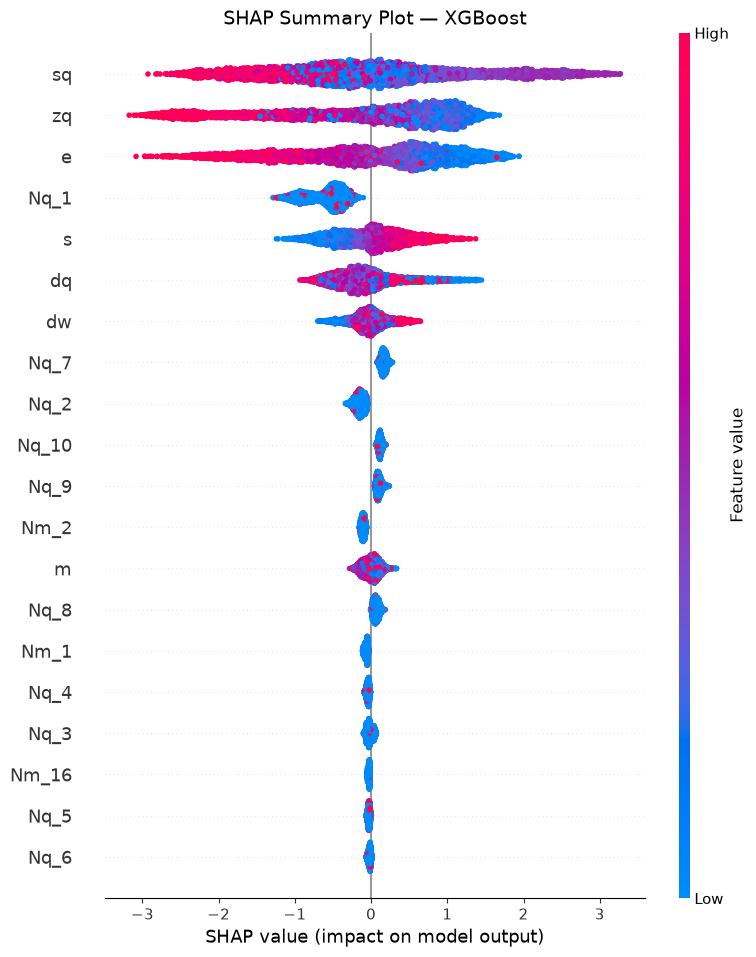

In [ ]:
### --- SHAP Summary Plot (Beeswarm) --- ###
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_array,
    X_train,
    show=False
)

plt.title("SHAP Summary Plot — XGBoost", fontsize=14, fontweigth='bold')
plt.tight_layout()
plt.show()

Reading the plot, **three features dominate: `sq`, `zq` and `e`**. Their effects are large (SHAP values of up to about 3 in log-odds) and they follow a clear tendency:

- **`zq`**: high values (red) push towards *non polymorphic*, and low values (blue) towards *polymorphic*.
- **`e`** (extinction rate): the same pattern, so frequent colony extinctions work against the maintenance of polymorphism.
- **`sq`**: high scaled values (an allele favouring queens) tend to push towards *non polymorphic*. The colours are more mixed than for `zq` and `e`, which hints at an effect that depends on other features.
- **`s`** (survival): the effect goes the other way, since higher survival tends to favour polymorphism.
- **`Nq_1`**: single-queen colonies lower the probability of polymorphism, whereas larger numbers of queens (such as `Nq_7`, `Nq_9`, `Nq_10`) have a small positive effect.
- **`dq` and `dw`** have a more moderate impact, and **`m`** and the `Nm` dummies are nearly irrelevant.

**Global importance.** Averaging the absolute SHAP values over the samples gives a single ranking of the features.

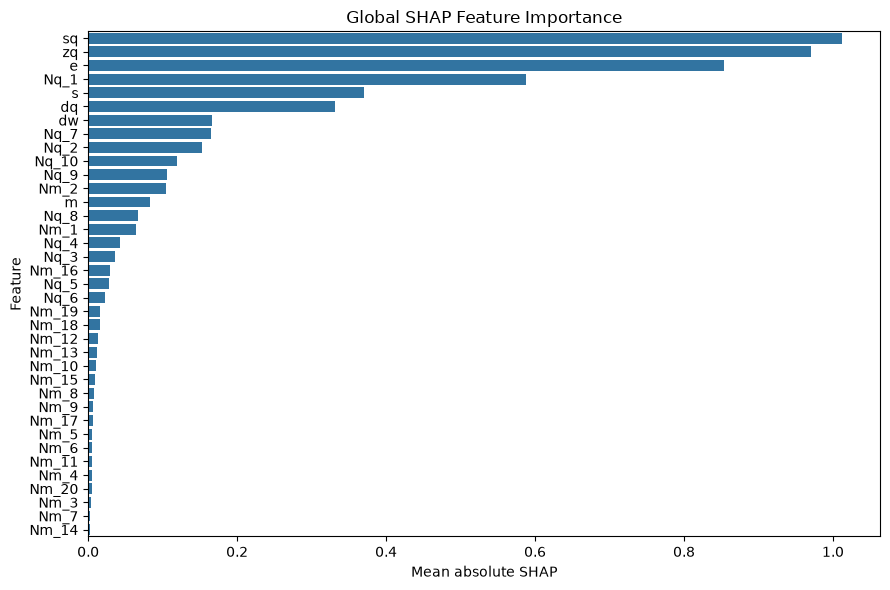

   Feature  Mean absolute SHAP
30      sq            1.012493
34      zq            0.970017
32       e            0.853096
0     Nq_1            0.588178
31       s            0.370380
36      dq            0.331064
35      dw            0.166356
6     Nq_7            0.165296
1     Nq_2            0.152887
9    Nq_10            0.118678
8     Nq_9            0.105202
11    Nm_2            0.104472
33       m            0.082479
7     Nq_8            0.067536
10    Nm_1            0.064180
3     Nq_4            0.042783
2     Nq_3            0.035716
25   Nm_16            0.029229
4     Nq_5            0.028611
5     Nq_6            0.021938
28   Nm_19            0.016316
27   Nm_18            0.016085
21   Nm_12            0.013818
22   Nm_13            0.012034
19   Nm_10            0.010833
24   Nm_15            0.009254
17    Nm_8            0.007579
18    Nm_9            0.006819
26   Nm_17            0.006645
14    Nm_5            0.005452
15    Nm_6            0.005368
20   Nm_

In [ ]:
### --- Global SHAP Feature Importance --- ###
shap_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Mean absolute SHAP": np.abs(shap_array).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean absolute SHAP",
    ascending=False
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=shap_importance,
    x="Mean absolute SHAP",
    y="Feature"
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

print(shap_importance)

The ranking confirms the beeswarm plot. The three leaders are **`sq` (about 1.01), `zq` (about 0.97) and `e` (about 0.85)**, followed by single-queen colonies **`Nq_1` (about 0.59)**, `s` (0.37), `dq` (0.33) and `dw` (0.17). The importance of `Nq` is spread over its ten dummy columns, so the number of queens matters more than any single bar suggests.

**Interaction values.** SHAP can also split each prediction into **main effects** (a feature alone) and **pairwise interaction effects** (the extra contribution of two features acting together). The result is a three-dimensional array: samples by features by features.

In [ ]:
### --- SHAP Interaction Values --- ###
interaction_values = explainer.shap_interaction_values(X_train)

# Handle possible binary-class output dimensions.
if isinstance(interaction_values, list):
    interaction_values = interaction_values[1]

interaction_values = np.asarray(interaction_values)

if interaction_values.ndim == 4:
    interaction_values = interaction_values[:, :, :, 1]

print("Interaction values shape:", interaction_values.shape)

Interaction values shape: (5058, 37, 37)


**Global interaction matrix.** The heatmap shows the mean absolute interaction value for every pair of features. The **diagonal** holds the main effects; the **off-diagonal** cells hold the interactions.

> **Note.** The figure is large (50 by 35 inches) so that the 37 x 37 annotations stay legible. Zoom in on it, or reduce `figsize` and the annotation size if you prefer a more compact version.

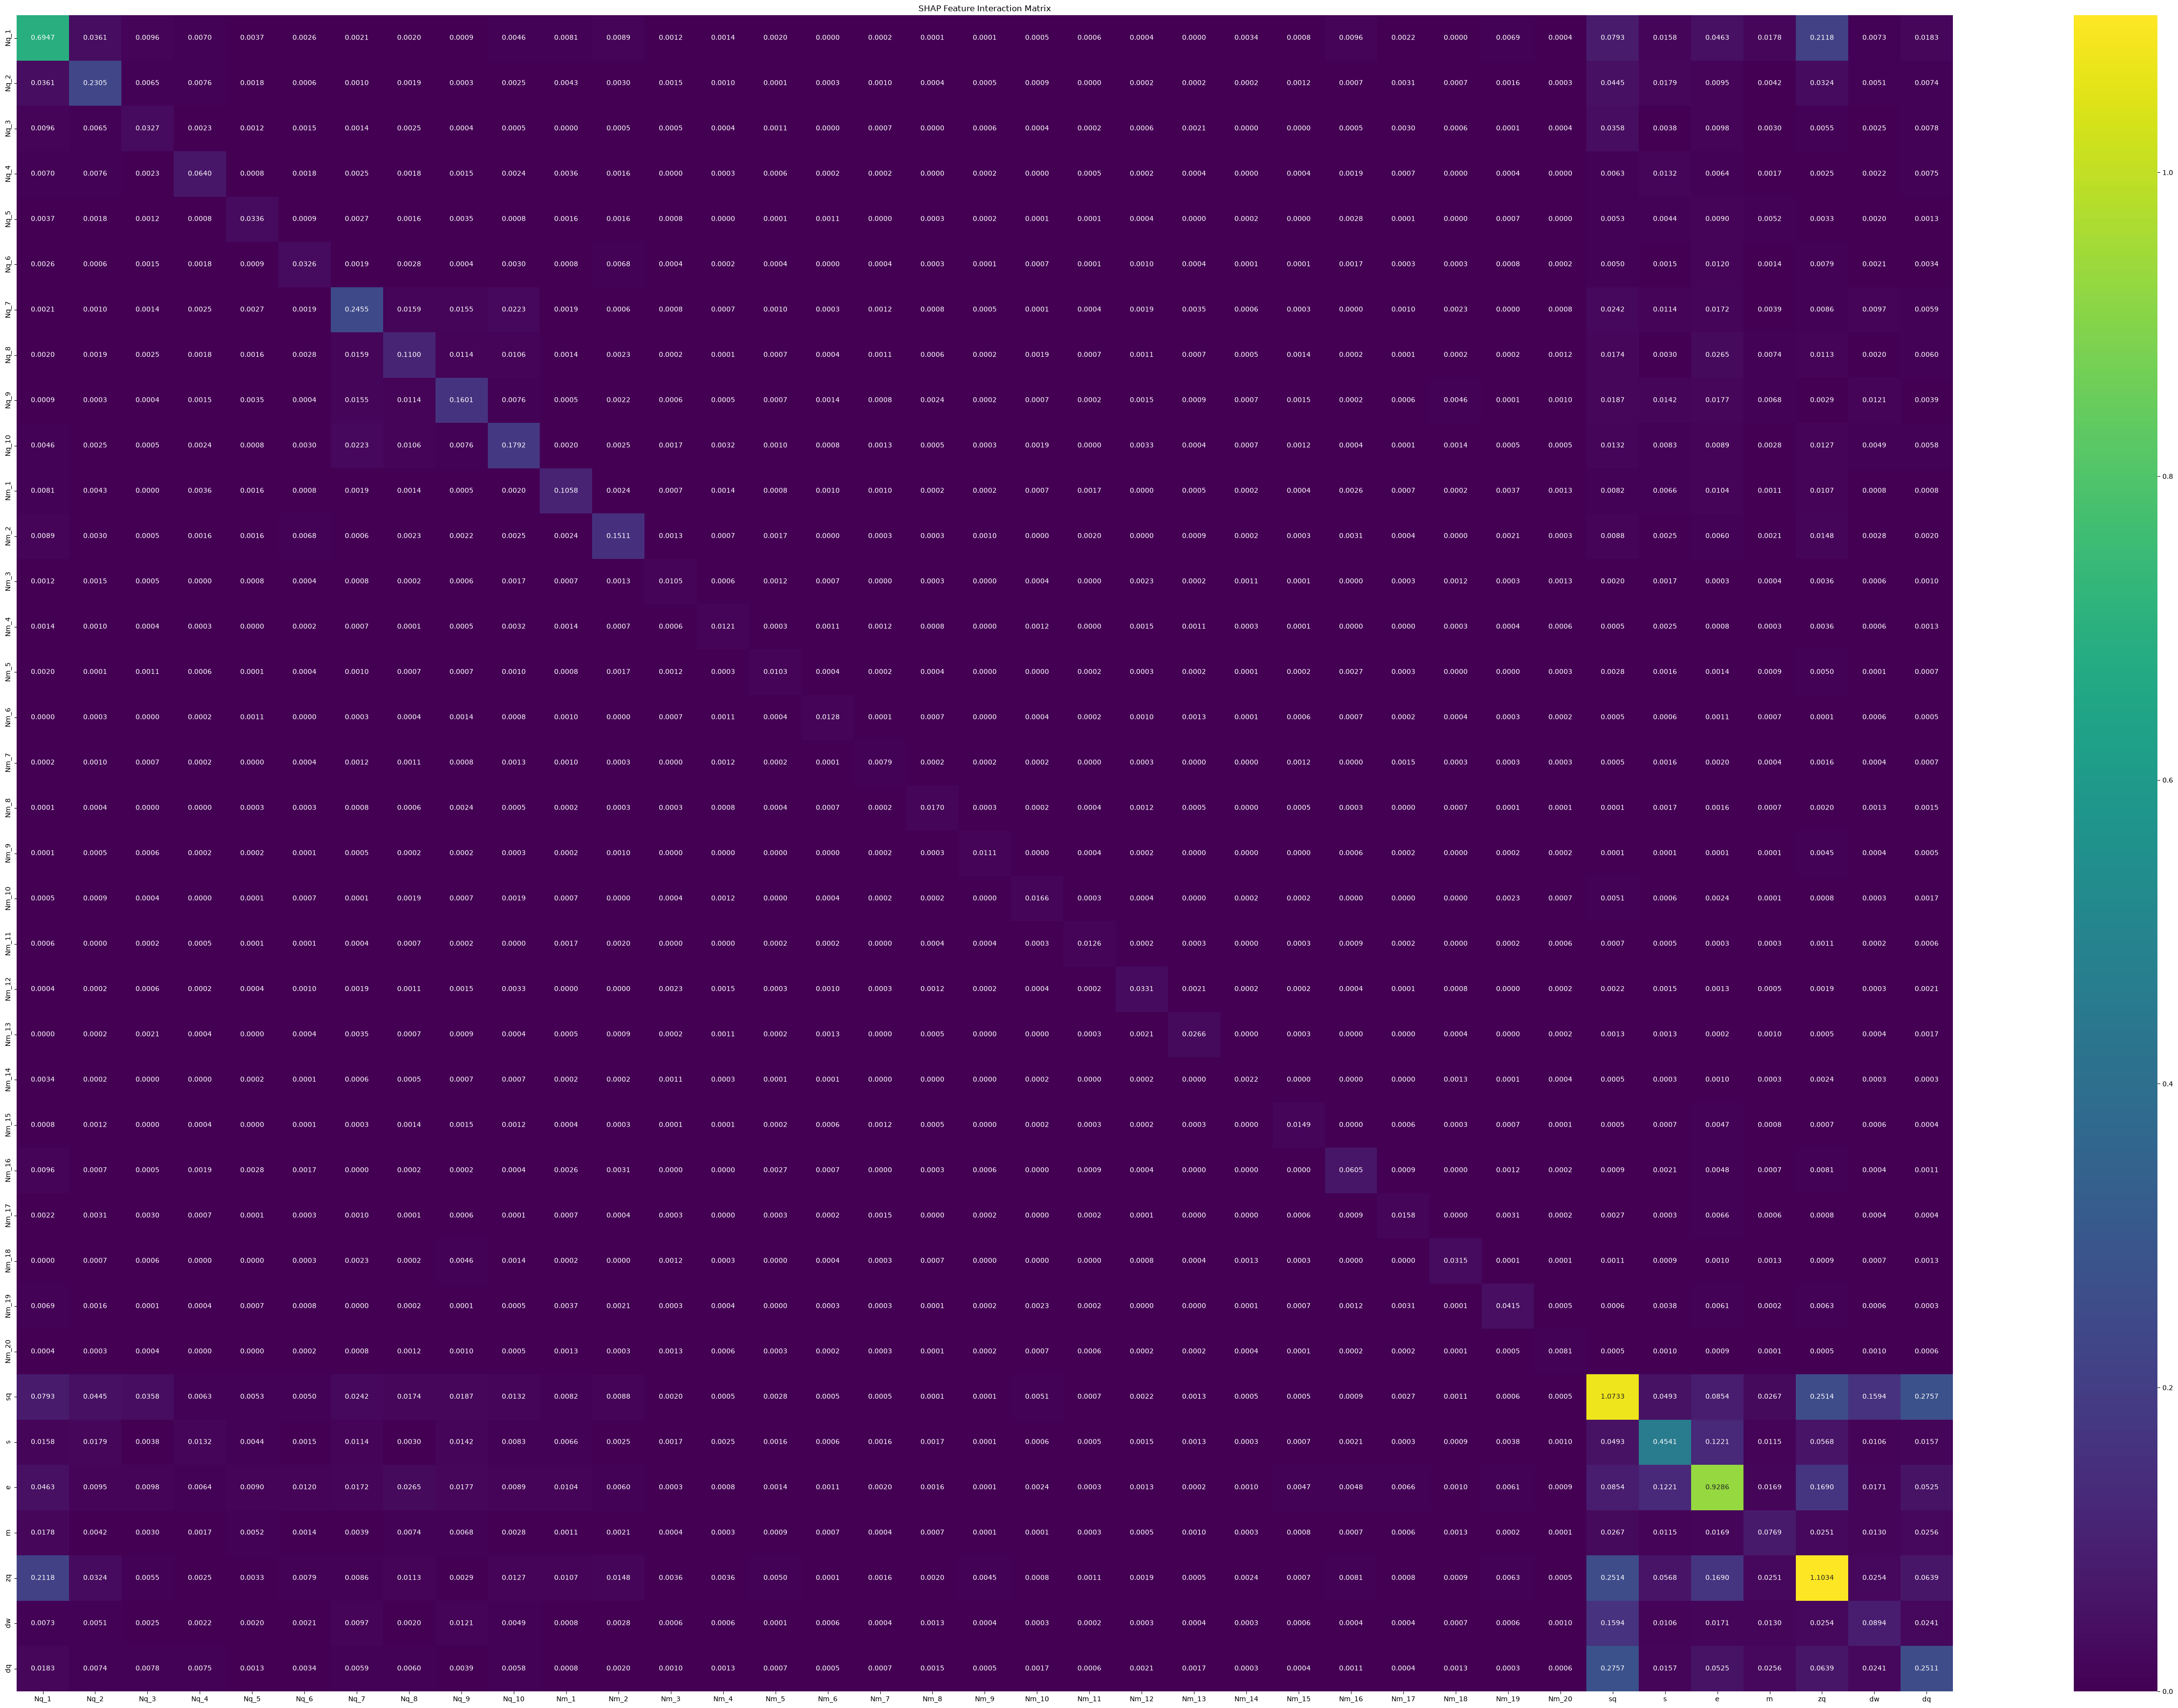

In [ ]:
### --- Global SHAP Interaction Matrix --- ###
mean_interactions = np.abs(interaction_values).mean(axis=0)

interaction_df = pd.DataFrame(
    mean_interactions,
    index=X_train.columns,
    columns=X_train.columns
)

plt.figure(figsize=(50, 35))

sns.heatmap(
    interaction_df,
    annot=True,
    fmt=".4f",
    cmap="viridis"
)

plt.title("SHAP Feature Interaction Matrix")
plt.tight_layout()
plt.show()

Apart from the main effects on the diagonal, the strongest pairwise interactions involve **`sq`** (with `dq`, `zq` and `dw`) and **`zq`** (with `Nq_1` and `e`). Interactions of this size confirm that the model does not treat the features independently, which is consistent with the weaker performance of the purely additive logistic regression. The presence of `dq` and `dw` among the main partners of `sq` motivates the next stage.

> **Takeaway (Stage 1).** Polymorphism is driven mainly by **the effect of the allele (`sq`), the phenotype of the castes (`zq`) and the extinction rate (`e`)**, with an important role for the number of queens and for survival. The dominance parameters `dq` and `dw` have a smaller direct impact but **interact with `sq`**.

### **11.3 Stage 2: Dominance and the Sign of the Allele Effect**

**The expectation.** If an allele is good for one caste and bad for the other, theory on antagonistic selection suggests that polymorphism is easiest to maintain when the allele is **dominant in the caste that it benefits** and **recessive in the caste that it harms** (*dominance reversal*). Applied to our model, this gives two predictions, which are the ones tested in the code below:

| Sign of `sq` | Allele favours | Expected relation for polymorphism |
|---|---|---|
| **Negative** | Workers | `dq < dw` |
| **Positive** | Queens | `dq > dw` |

**The approach.** We cannot test this expectation on the simulation directly, so we ask the model. We (1) look at how the effects of `dq` and `dw` change with `sq`, (2) draw the predicted probability of polymorphism over the whole `dq` by `dw` plane, separately for each sign of `sq`, and (3) compare the predictions with the observed outcomes on the test set.

**SHAP dependence plots.** These plots show the SHAP value of one feature against its value, coloured by a second feature. If the colours form a clear gradient at a given x position, the effect of the feature depends on the coloured one. Here we plot `dq` and `dw`, both coloured by `sq`.

<Figure size 900x700 with 0 Axes>

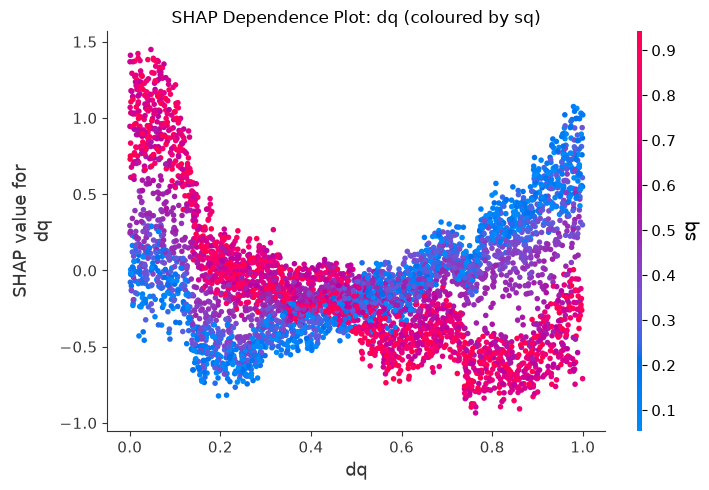

In [ ]:
### --- SHAP Dependence Plot: dq Coloured by sq --- ###
plt.figure(figsize=(9, 7))

shap.dependence_plot(
    "dq",
    shap_array,
    X_train,
    interaction_index="sq",
    show=False
)

plt.title("SHAP Dependence Plot: dq (coloured by sq)")
plt.tight_layout()
plt.show()

<Figure size 900x700 with 0 Axes>

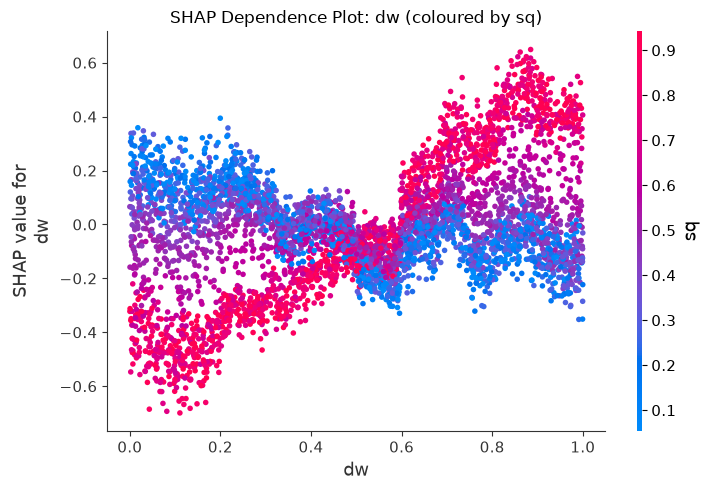

In [ ]:
### --- SHAP Dependence Plot: dw Coloured by sq --- ###
plt.figure(figsize=(9, 7))

shap.dependence_plot(
    "dw",
    shap_array,
    X_train,
    interaction_index="sq",
    show=False
)

plt.title("SHAP Dependence Plot: dw (coloured by sq)")
plt.tight_layout()
plt.show()

**SHAP interaction dependence plots.** These plots go one step further and isolate the **pure interaction** between two features: `dq` x `sq` and `dw` x `sq`. Points above the dashed zero line mean that the combination of the two features pushes towards polymorphism beyond their separate effects, and points below the line mean the opposite. The colour shows the value of `sq`.

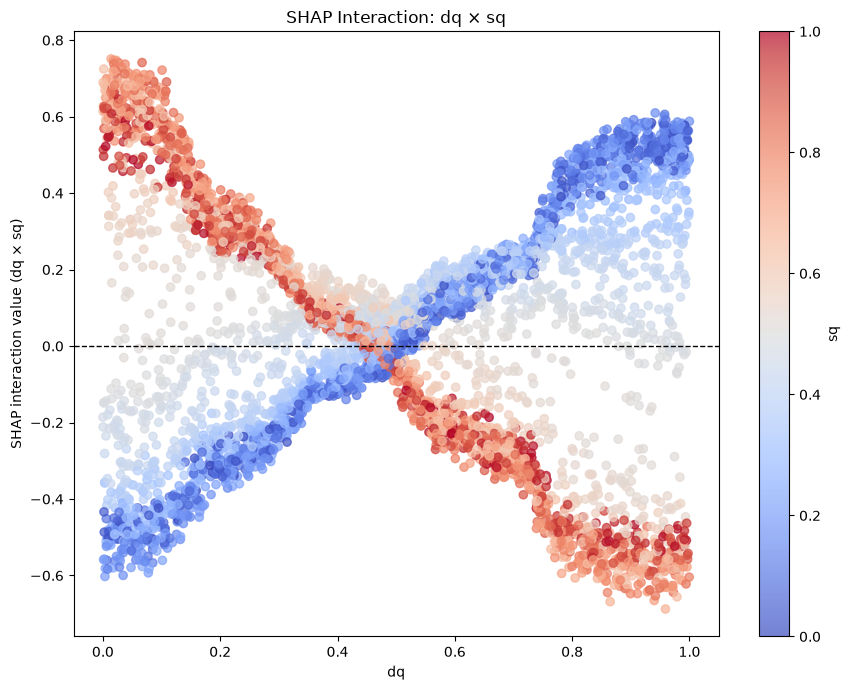

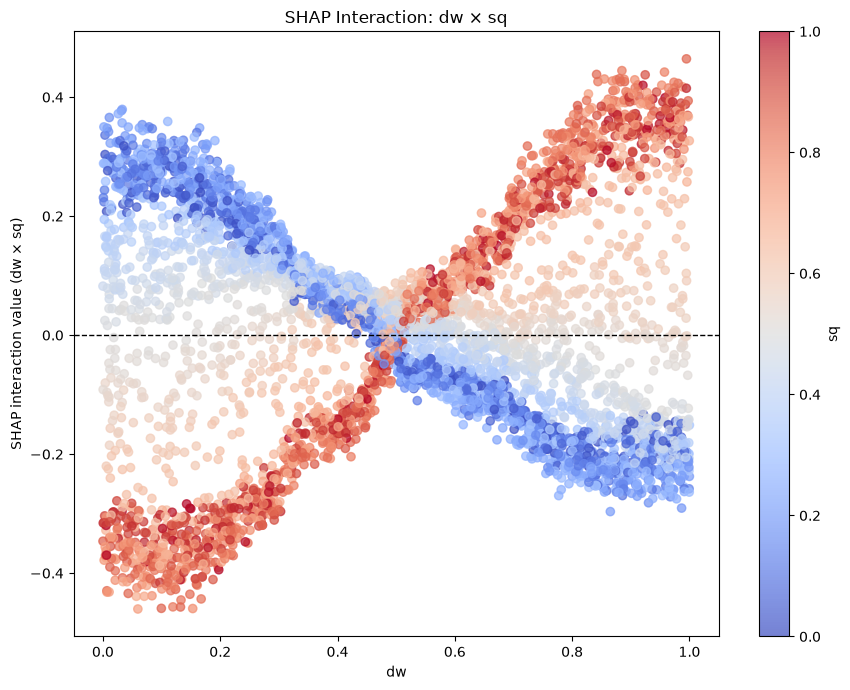

In [ ]:
### --- SHAP Interaction Dependence Plots (dq x sq and dw x sq) --- ###
# Get feature positions.
dq_idx = X_train.columns.get_loc("dq")
dw_idx = X_train.columns.get_loc("dw")
sq_idx = X_train.columns.get_loc("sq")

# dq × sq interaction
plt.figure(figsize=(9, 7))

plt.scatter(
    X_train["dq"],
    interaction_values[:, dq_idx, sq_idx],
    c=X_train["sq"],
    cmap="coolwarm",
    alpha=0.7
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("dq")
plt.ylabel("SHAP interaction value (dq × sq)")
plt.title("SHAP Interaction: dq × sq")
plt.colorbar(label="sq")

plt.tight_layout()
plt.show()

# dw × sq interaction
plt.figure(figsize=(9, 7))

plt.scatter(
    X_train["dw"],
    interaction_values[:, dw_idx, sq_idx],
    c=X_train["sq"],
    cmap="coolwarm",
    alpha=0.7
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("dw")
plt.ylabel("SHAP interaction value (dw × sq)")
plt.title("SHAP Interaction: dw × sq")
plt.colorbar(label="sq")

plt.tight_layout()
plt.show()

**Conditional prediction surfaces.** For each sign of `sq`, we take the training samples with that sign, set `dq` and `dw` to every value of a 40 x 40 grid while **keeping all the other features at their observed values**, and average the predicted probability of polymorphism. The result is a map of the model's belief over the `dq` by `dw` plane. The black contour marks the probability of 0.5, and the dashed diagonal is the line `dq = dw`.

> **Note.** `sq` is min-max scaled in the model, so the value 0.5 of the scaled variable corresponds to an allele effect of 0. A **negative** `sq` corresponds to scaled values below 0.5, and a **positive** `sq` to values above.

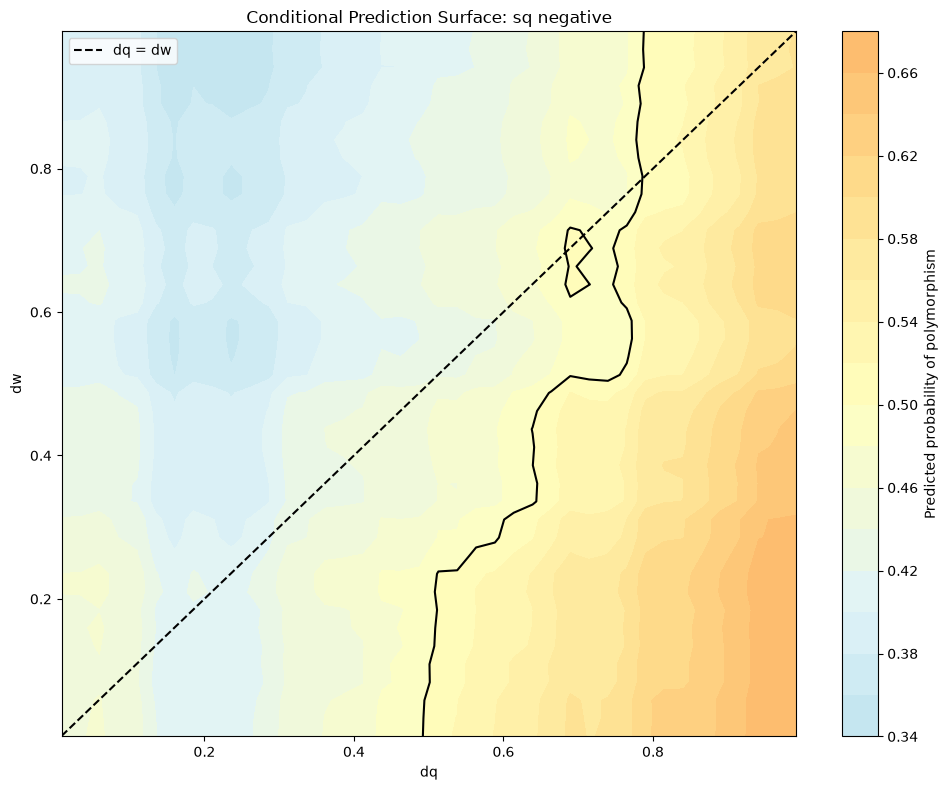

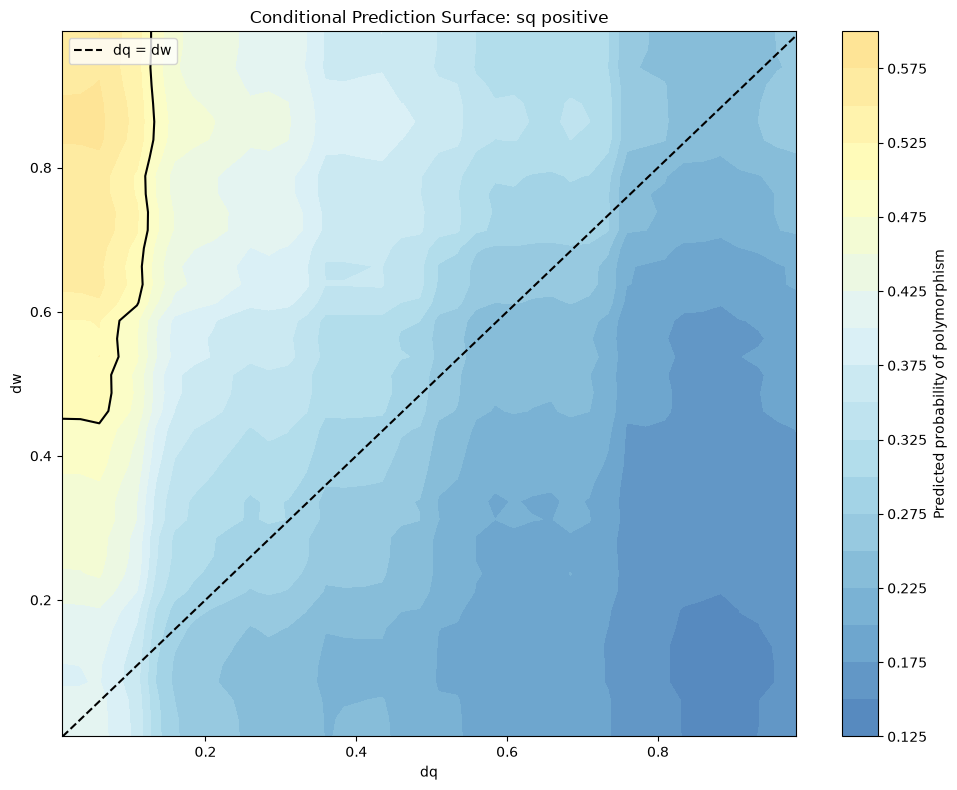

In [ ]:
### --- Conditional Prediction Surfaces --- ###
# Identify the positive class.
positive_class = 1

class_idx = np.where(
    best_xgb_model.classes_ == positive_class
)[0][0]

def conditional_prediction_surface(
    model,
    X,
    sq_condition,
    condition_name,
    class_idx,
    grid_size=40,
    max_background=500
):

    # Select observations according to sq.
    if sq_condition == "negative":
        subset = X[X["sq"] < 0.5].copy()

    elif sq_condition == "positive":
        subset = X[X["sq"] > 0.5].copy()

    else:
        raise ValueError("Condition must be negative or positive.")

    if len(subset) == 0:
        raise ValueError(f"No observations with sq {condition_name}.")

    # Limit background observations to reduce computation.
    background = subset.sample(
        n=min(len(subset), max_background),
        random_state=random_seed
    )

    # Define dq and dw ranges within the selected subgroup.
    dq_min, dq_max = subset["dq"].quantile([0.01, 0.99])
    dw_min, dw_max = subset["dw"].quantile([0.01, 0.99])

    dq_grid = np.linspace(dq_min, dq_max, grid_size)
    dw_grid = np.linspace(dw_min, dw_max, grid_size)

    prediction_grid = np.zeros(
        (grid_size, grid_size)
    )

    # Generate predictions for every dq/dw combination.
    for i, dq_value in enumerate(dq_grid):

        for j, dw_value in enumerate(dw_grid):

            # Preserve other features from actual observations.
            X_modified = background.copy()

            X_modified["dq"] = dq_value
            X_modified["dw"] = dw_value

            # Average predicted probability.
            probabilities = model.predict_proba(
                X_modified
            )[:, class_idx]

            prediction_grid[j, i] = probabilities.mean()

    # Plot surface.
    plt.figure(figsize=(10, 8))

    contour = plt.contourf(
        dq_grid,
        dw_grid,
        prediction_grid,
        levels=20,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=1
    )

    # Decision probability threshold.
    plt.contour(
        dq_grid,
        dw_grid,
        prediction_grid,
        levels=[0.5],
        colors="black",
        linewidths=1.5
    )

    # Hypothesised relationship: dq = dw.
    diagonal_min = max(dq_min, dw_min)
    diagonal_max = min(dq_max, dw_max)

    if diagonal_min < diagonal_max:
        diagonal = np.linspace(
            diagonal_min,
            diagonal_max,
            100
        )

        plt.plot(
            diagonal,
            diagonal,
            "k--",
            linewidth=1.5,
            label="dq = dw"
        )

    plt.colorbar(
        contour,
        label="Predicted probability of polymorphism"
    )

    plt.xlabel("dq")
    plt.ylabel("dw")

    plt.title(
        f"Conditional Prediction Surface: sq {condition_name}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

    return dq_grid, dw_grid, prediction_grid

# Surface A: Negative sq
surface_negative = conditional_prediction_surface(
    best_xgb_model,
    X_train,
    "negative",
    "negative",
    class_idx
)

# Surface B: Positive sq
surface_positive = conditional_prediction_surface(
    best_xgb_model,
    X_train,
    "positive",
    "positive",
    class_idx
)

**Difference between the two surfaces.** To compare them directly, the surface for positive `sq` is interpolated onto the grid of the negative one, and then subtracted: *positive `sq` minus negative `sq`*. Red areas are combinations of `dq` and `dw` where a positive `sq` makes polymorphism **more** likely, blue areas where it makes polymorphism **less** likely.

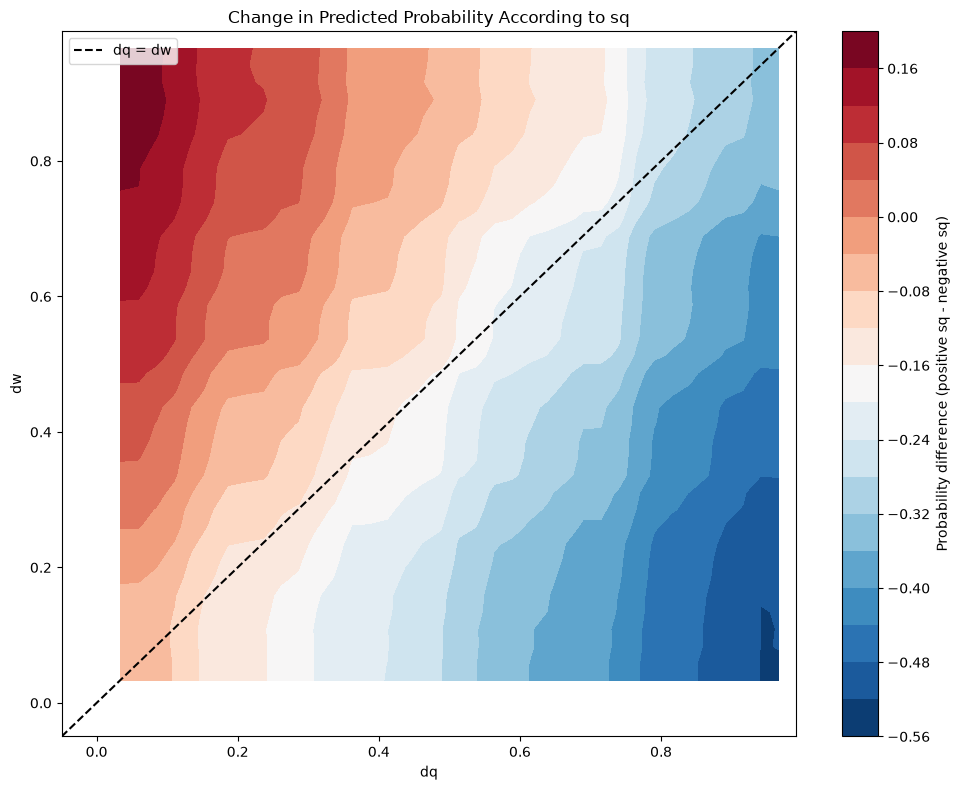

In [ ]:
### --- Difference Between the Two Prediction Surfaces --- ###
dq_grid_neg, dw_grid_neg, prob_negative = surface_negative
dq_grid_pos, dw_grid_pos, prob_positive = surface_positive

# Both surfaces use the same grid size, but their ranges differ.
# Interpolate positive surface onto the negative surface grid.

positive_interpolator = RegularGridInterpolator(
    (dw_grid_pos, dq_grid_pos),
    prob_positive,
    bounds_error=False,
    fill_value=np.nan
)

DQ, DW = np.meshgrid(
    dq_grid_neg,
    dw_grid_neg
)

grid_points = np.column_stack([
    DW.ravel(),
    DQ.ravel()
])

prob_positive_interpolated = positive_interpolator(
    grid_points
).reshape(DQ.shape)

difference = prob_positive_interpolated - prob_negative

plt.figure(figsize=(10, 8))

contour = plt.contourf(
    dq_grid_neg,
    dw_grid_neg,
    difference,
    levels=20,
    cmap="RdBu_r"
)

plt.colorbar(
    contour,
    label="Probability difference (positive sq - negative sq)"
)

plt.axline(
    (0, 0),
    slope=1,
    color="black",
    linestyle="--",
    label="dq = dw"
)

plt.xlabel("dq")
plt.ylabel("dw")
plt.title("Change in Predicted Probability According to sq")

plt.legend()
plt.tight_layout()
plt.show()

The map has a clear structure. A positive `sq` **raises** the predicted probability of polymorphism in the upper-left part of the plane (low `dq`, high `dw`, so `dq < dw`) and **lowers** it in the lower-right part (high `dq`, low `dw`, so `dq > dw`), with the largest drops in the bottom-right corner. The effect of the sign of `sq` therefore depends strongly on the relation between `dq` and `dw`, which confirms the interaction detected by SHAP.

The next cell quantifies this difference.

In [ ]:
### --- Quantifying the Surface Difference --- ###
mean_difference = np.nanmean(difference)
median_difference = np.nanmedian(difference)
minimum_difference = np.nanmin(difference)
maximum_difference = np.nanmax(difference)
mean_absolute_difference = np.nanmean(np.abs(difference))

print("Surface comparison")
print("------------------")
print(f"Mean difference:        {mean_difference:.4f}")
print(f"Median difference:      {median_difference:.4f}")
print(f"Mean absolute difference: {mean_absolute_difference:.4f}")
print(f"Minimum difference:     {minimum_difference:.4f}")
print(f"Maximum difference:     {maximum_difference:.4f}")

Surface comparison
------------------
Mean difference:        -0.1812
Median difference:      -0.1768
Mean absolute difference: 0.2086
Minimum difference:     -0.5215
Maximum difference:     0.1814


On average, the predicted probability is **about 0.18 lower** for positive `sq` than for negative `sq` (mean and median difference of about -0.18; mean absolute difference of about 0.21). The difference ranges from **-0.52 to +0.18**, so the swing in the lower-right corner is much larger than in the upper-left one.

**Observed conditions on the test set.** We now go back to the real test data. Each sample is assigned to one of four conditions according to the sign of `sq` and to whether `dq` is smaller or larger than `dw`.

In [ ]:
### --- Observations by Sign of sq and dq / dw Relation --- ###
relationship_data = X_test_original.copy()

relationship_data["sq_sign"] = np.where(
    relationship_data["sq"] < 0,
    "Negative sq",
    "Positive sq"
)

relationship_data["D"] = (
    relationship_data["dq"] - relationship_data["dw"]
)

relationship_data["dq_dw_relation"] = np.where(
    relationship_data["D"] < 0,
    "dq < dw",
    np.where(
        relationship_data["D"] > 0,
        "dq > dw",
        "dq = dw"
    )
)

relationship_data["condition"] = (
    relationship_data["sq_sign"]
    + " / "
    + relationship_data["dq_dw_relation"]
)

print(
    relationship_data["condition"].value_counts()
)

condition
Negative sq / dq > dw    196
Positive sq / dq < dw    133
Negative sq / dq < dw    121
Positive sq / dq > dw    112
Name: count, dtype: int64


The 562 test samples are spread over four conditions of comparable size (from 112 to 196 samples). This was expected, since all parameters were drawn independently of each other, and it means that every condition has enough samples to be compared. The scatter plot below shows the same information in the `dq` by `dw` plane.

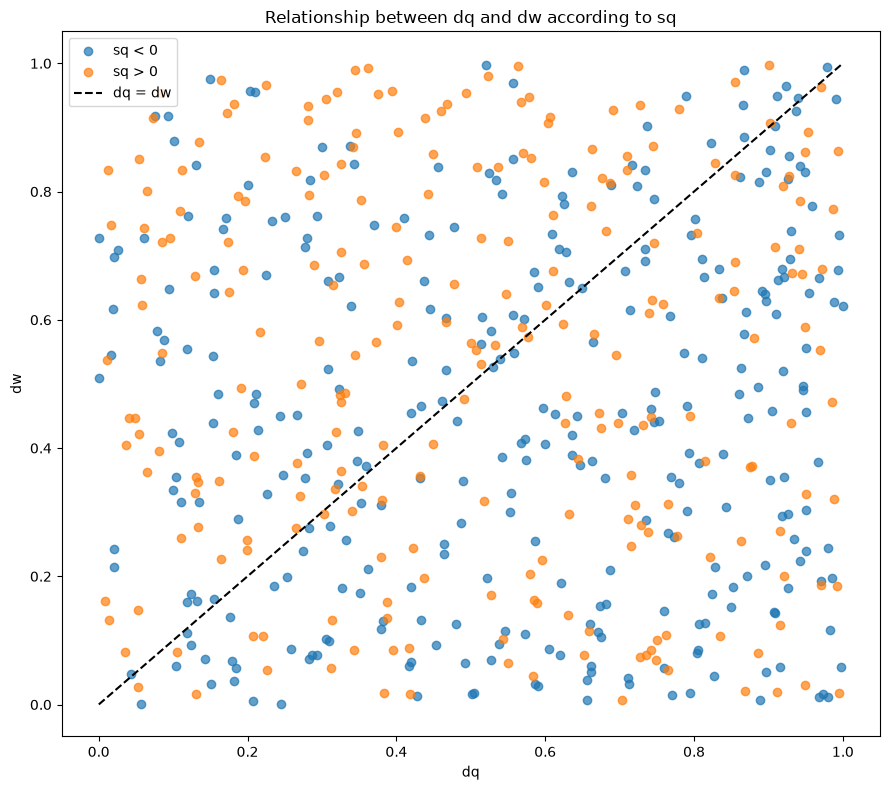

In [ ]:
### --- dq Versus dw Coloured by Sign of sq --- ###
plt.figure(figsize=(9, 8))

negative = relationship_data[
    relationship_data["sq"] < 0
]

positive = relationship_data[
    relationship_data["sq"] > 0
]

plt.scatter(
    negative["dq"],
    negative["dw"],
    label="sq < 0",
    alpha=0.7
)

plt.scatter(
    positive["dq"],
    positive["dw"],
    label="sq > 0",
    alpha=0.7
)

# Diagonal dq = dw
minimum = min(
    relationship_data["dq"].min(),
    relationship_data["dw"].min()
)

maximum = max(
    relationship_data["dq"].max(),
    relationship_data["dw"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="dq = dw"
)

plt.xlabel("dq")
plt.ylabel("dw")
plt.title("Relationship between dq and dw according to sq")
plt.legend()
plt.tight_layout()
plt.show()

**Predicted probability by condition.** The boxplots show how the model's predicted probability of polymorphism is distributed in each of the four conditions.

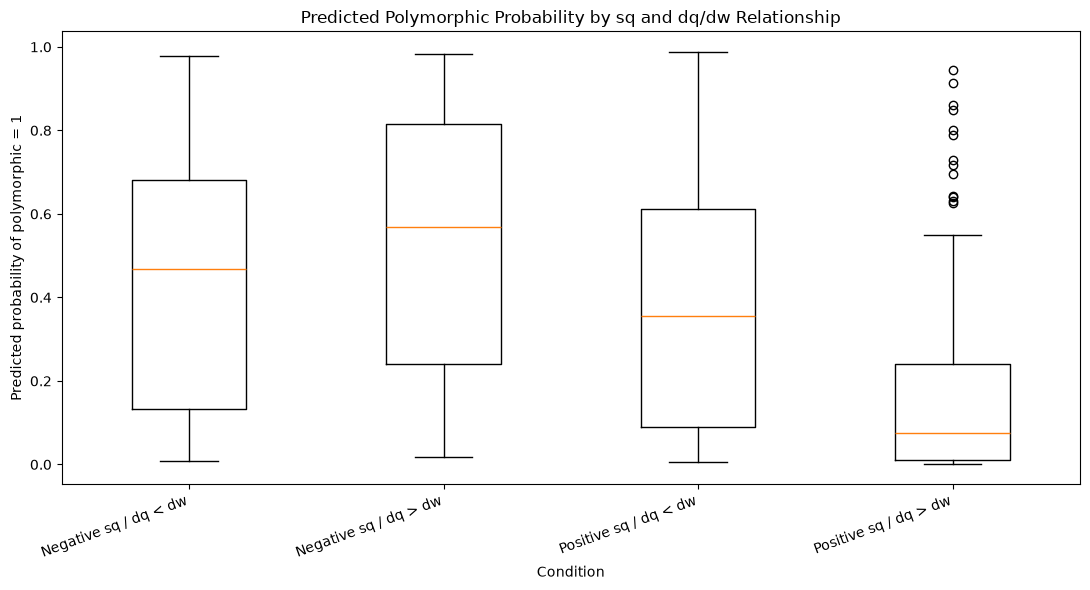

In [ ]:
### --- Predicted Probability by Condition --- ###
# Calculate predicted probabilities if not already present
class_1_index = list(best_xgb_model.classes_).index(1)

relationship_data["predicted_probability"] = (
    best_xgb_model.predict_proba(X_test)[:, class_1_index]
)

# Define the four conditions
condition_order = [
    "Negative sq / dq < dw",
    "Negative sq / dq > dw",
    "Positive sq / dq < dw",
    "Positive sq / dq > dw"
]

# Construct condition labels
relationship_data["condition_plot"] = (
    relationship_data["sq_sign"]
    + " / "
    + relationship_data["dq_dw_relation"]
)

# Keep only the four conditions
plot_data = relationship_data[
    relationship_data["condition_plot"].isin(condition_order)
].copy()

# Prepare boxplot data
data_to_plot = [
    plot_data.loc[
        plot_data["condition_plot"] == condition,
        "predicted_probability"
    ].dropna().values
    for condition in condition_order
]

# Plot
plt.figure(figsize=(11, 6))

plt.boxplot(
    data_to_plot,
    tick_labels=condition_order
)

plt.ylabel("Predicted probability of polymorphic = 1")
plt.xlabel("Condition")
plt.title(
    "Predicted Polymorphic Probability by sq and dq/dw Relationship"
)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Predicted versus observed polymorphism rates.** The final check compares, for each condition, the mean predicted probability with the **observed share of polymorphic samples**. The sample size `n` is written above each pair of bars.

                         n  predicted  observed
condition_plot                                 
Negative sq / dq < dw  121   0.438078  0.495868
Negative sq / dq > dw  196   0.528928  0.632653
Positive sq / dq < dw  133   0.384465  0.458647
Positive sq / dq > dw  112   0.186823  0.187500


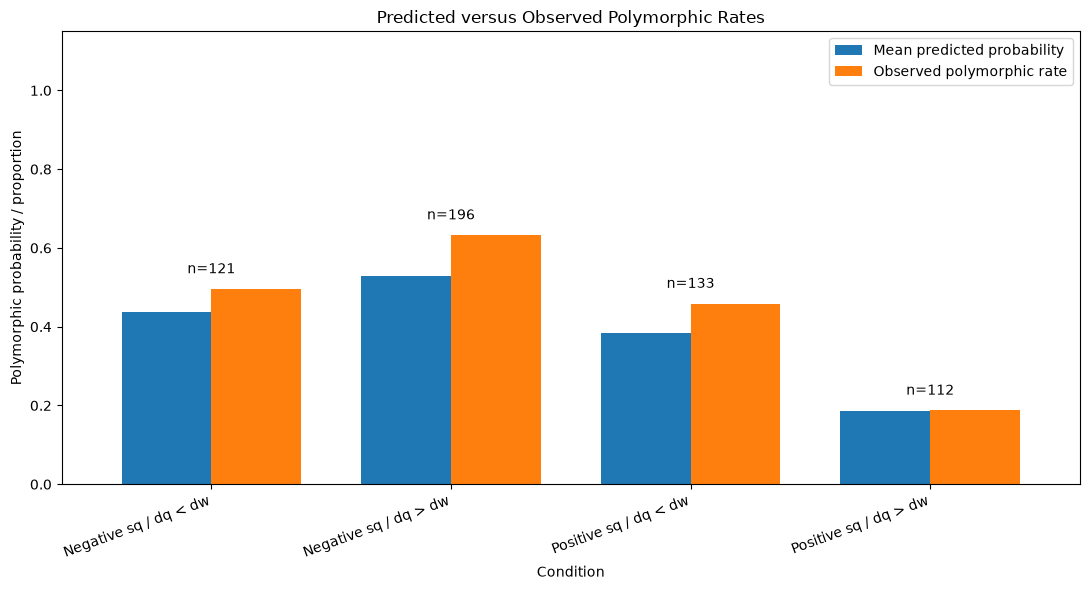

In [ ]:
### --- Predicted Versus Observed Polymorphic Rates --- ###
# Calculate predicted probabilities
class_1_index = list(best_xgb_model.classes_).index(1)

relationship_data["predicted_probability"] = (
    best_xgb_model.predict_proba(X_test)[:, class_1_index]
)

# Add actual observed classes
relationship_data["observed_class"] = (
    np.asarray(y_test).reshape(-1)
)

# Create condition labels if not already available
relationship_data["condition_plot"] = (
    relationship_data["sq_sign"]
    + " / "
    + relationship_data["dq_dw_relation"]
)

# Calculate summary statistics
comparison = (
    relationship_data
    .groupby("condition_plot")
    .agg(
        n=("observed_class", "size"),
        predicted=("predicted_probability", "mean"),
        observed=("observed_class", "mean")
    )
    .reindex(condition_order)
)

print(comparison)

# Plot comparison
comparison_plot = comparison.dropna(
    subset=["predicted", "observed"]
)

ax = comparison_plot[
    ["predicted", "observed"]
].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

# Add sample sizes
for i, (_, row) in enumerate(comparison_plot.iterrows()):
    height = max(row["predicted"], row["observed"])

    ax.text(
        i,
        height + 0.04,
        f'n={int(row["n"])}',
        ha="center",
        fontsize=10
    )

plt.ylabel("Polymorphic probability / proportion")
plt.xlabel("Condition")
plt.title("Predicted versus Observed Polymorphic Rates")

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.15)

plt.legend([
    "Mean predicted probability",
    "Observed polymorphic rate"
])

plt.tight_layout()
plt.show()

| Condition | n | Mean predicted | Observed |
|---|---|---|---|
| Negative `sq` / `dq < dw` | 121 | 0.44 | 0.50 |
| Negative `sq` / `dq > dw` | 196 | 0.53 | 0.63 |
| Positive `sq` / `dq < dw` | 133 | 0.38 | 0.46 |
| Positive `sq` / `dq > dw` | 112 | 0.19 | 0.19 |

Two observations follow. First, the model **follows the observed ordering of the four conditions** and is well calibrated for the lowest one; elsewhere it under-estimates the observed rate by 6 to 10 percent. Second, and more importantly, the pattern is **the reverse of the dominance-reversal expectation**: for negative `sq`, polymorphism is more frequent when `dq > dw` (0.63) than when `dq < dw` (0.50), and for positive `sq` it is much more frequent when `dq < dw` (0.46) than when `dq > dw` (0.19).

**Evaluating the expectation.** For each sign of `sq`, the next cell computes the share of test samples that satisfy the expected relation, and Fisher's exact test is then applied to the corresponding 2 x 2 table.

In [ ]:
### --- Evaluating the Dominance Expectation --- ###
negative_sq = relationship_data[
    relationship_data["sq"] < 0
]

positive_sq = relationship_data[
    relationship_data["sq"] > 0
]

negative_expected = (
    negative_sq["dq"] < negative_sq["dw"]
).mean()

positive_expected = (
    positive_sq["dq"] > positive_sq["dw"]
).mean()

print("Hypothesis evaluation")
print("---------------------")

print(
    f"Negative sq: dq < dw in "
    f"{negative_expected * 100:.2f}% of observations "
    f"(n = {len(negative_sq)})"
)

print(
    f"Positive sq: dq > dw in "
    f"{positive_expected * 100:.2f}% of observations "
    f"(n = {len(positive_sq)})"
)

### --- Fisher's Exact Test --- ###
negative_expected_count = (
    negative_sq["dq"] < negative_sq["dw"]
).sum()

negative_opposite_count = (
    negative_sq["dq"] > negative_sq["dw"]
).sum()

positive_expected_count = (
    positive_sq["dq"] > positive_sq["dw"]
).sum()

positive_opposite_count = (
    positive_sq["dq"] < positive_sq["dw"]
).sum()

contingency_table = [
    [negative_expected_count, negative_opposite_count],
    [positive_expected_count, positive_opposite_count]
]

odds_ratio, p_value = fisher_exact(contingency_table)

print("Contingency table:")
print(contingency_table)

print(f"\nOdds ratio: {odds_ratio:.4f}")
print(f"P-value: {p_value:.5f}")

Hypothesis evaluation
---------------------
Negative sq: dq < dw in 38.17% of observations (n = 317)
Positive sq: dq > dw in 45.71% of observations (n = 245)
Contingency table:
[[np.int64(121), np.int64(196)], [np.int64(112), np.int64(133)]]

Odds ratio: 0.7331
P-value: 0.08414


Among the samples with a negative `sq`, only **38.2%** satisfy the expected relation `dq < dw` (n = 317), and among those with a positive `sq`, only **45.7%** satisfy `dq > dw` (n = 245). Fisher's exact test returns an **odds ratio of 0.73** and a **p-value of 0.084**, which is not significant at the usual 5% level.

> **Note on interpretation.** This test describes how the test samples are distributed across the four conditions; it does not condition on the outcome. The evidence about polymorphism itself is the table of predicted and observed rates above, which is where the reversed pattern shows up. Both views agree that there is **no support for the expectation** in its simple form.

> **Takeaway (Stage 2).** The sign of `sq` and the relation between `dq` and `dw` clearly interact, both in the model (large differences between the prediction surfaces) and in the data (observed rates from 0.19 to 0.63). However, the direction of this interaction is **not the one predicted by the simple dominance-reversal argument**; if anything it is the opposite one. Explaining this reversal, for instance through the ecological parameters that also shape polymorphism, is a natural direction for further work.

> **XGBoost synthesis.** XGBoost improves the accuracy by about 4 percents over the random forest and, thanks to SHAP, **keeps a high level of biological interpretability**: we know which parameters matter, in which direction they act, and which of them interact.

## **12. Multilayer Perceptron**

As a last model, we train a **multilayer perceptron** (MLP), a feed-forward neural network. It can represent very flexible non-linear relationships, but it needs more data than tree ensembles to shine and is the hardest to interpret. We search over the architecture (from one layer of 30 neurons to two layers of 100), the activation function, the L2 penalty `alpha`, the learning rate, the number of epochs and the optimiser, with **early stopping** enabled to limit overfitting. The search uses 30 random combinations and 5-fold cross-validation.

In [ ]:
### --- Best Multilayer Perceptron --- ###

### --- Hyperparameter Tuning --- ###
# Define the hyperparameter search space for the MLP.
param_dist_mlp = {
    'hidden_layer_sizes': [(30,), (50,), (100,), (50, 25), 
                           (100, 50), (100, 100)],           # Network architecture.
    'activation': ['relu', 'tanh'],                          # Activation functions.
    'alpha': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0],       # L2 regularization strength (prevents overfitting).
    'learning_rate_init': [0.0001, 0.001, 0.01, 0.05],       # Initial learning rate.
    'max_iter': [500, 800],                                  # Max training epochs.
    'solver': ['adam', 'sgd']                                # Optimizers.
}

# Let's randomly search the hyperparameter space.
mlp_base = MLPClassifier(random_state = random_seed, early_stopping = True)
mlp_opt = RandomizedSearchCV(
    estimator = mlp_base,
    param_distributions = param_dist_mlp,
    n_iter = 30,
    cv = 5,
    scoring = 'accuracy',
    random_state = random_seed,
    n_jobs = -1
)

# Fit the random search.
print("------ Running Randomized Search for Multilayer Perceptron ------")
search_mlp = mlp_opt.fit(X_train, y_train['polymorphic'])
best_mlp_model = search_mlp.best_estimator_ # Best model.
best_mlp_params = search_mlp.best_params_   # Best hyperparameters set.
print(f"\nBest Hyperparameters Found: {best_mlp_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train['polymorphic'], best_mlp_model.predict(X_train)) # Whole training set accuracy.
CVval_acc = search_mlp.best_score_                                                      # Best cross validation accuracy.
test_acc  = accuracy_score(y_test['polymorphic'], best_mlp_model.predict(X_test))   # Testing set accuracy.

print('------ Set Accuracies for MLP ------')
print(f'Train Accuracy:              {train_acc:.4f}')
print(f'Cross-validation Accuracy:   {CVval_acc:.4f}')
print(f'Test Accuracy:               {test_acc:.4f}\n')

------ Running Randomized Search for Multilayer Perceptron ------

Best Hyperparameters Found: {'solver': 'adam', 'max_iter': 500, 'learning_rate_init': 0.01, 'hidden_layer_sizes': (50, 25), 'alpha': 0.1, 'activation': 'tanh'}

------ Set Accuracies for MLP ------
Train Accuracy:              0.9156
Cross-validation Accuracy:   0.8138
Test Accuracy:               0.8737



In the reference run, the best network (two hidden layers of 50 and 25 neurons, `tanh` activation, Adam optimiser, `alpha = 0.1`) reached a **test accuracy of about 87%** and a training accuracy of about 92%. This is **slightly below XGBoost** (about 88%), so the more flexible model does not bring any further gain on this dataset.

### **12.1 Confusion Matrix**

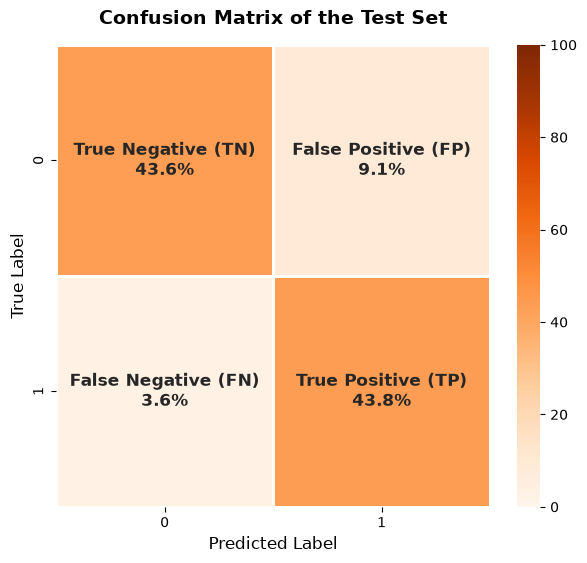

In [ ]:
### --- Confusion Matrix for Multilayer Perceptron --- ###
plot_confusion_matrix(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

### **12.2 ROC Curve**

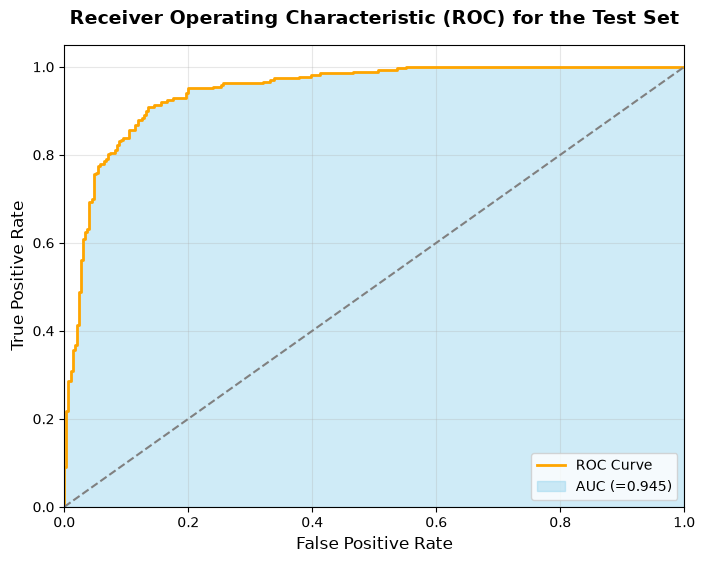

In [ ]:
### --- ROC Curve for Multilayer Perceptron --- ###
plot_roc(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

### **12.3 Permutation Importance**

An MLP has no built-in feature importance. **Permutation importance** provides an equivalent: each feature is shuffled in turn on the test set, and the **drop in accuracy** measures how much the model relied on it.

> **Note.** After Section 11.1, `X_test` already carries cleaned feature names (`Nm_1` rather than `one_hot__Nm_1`), so the cell reads them directly from `X_test`. Re-run the cell to display the figure.

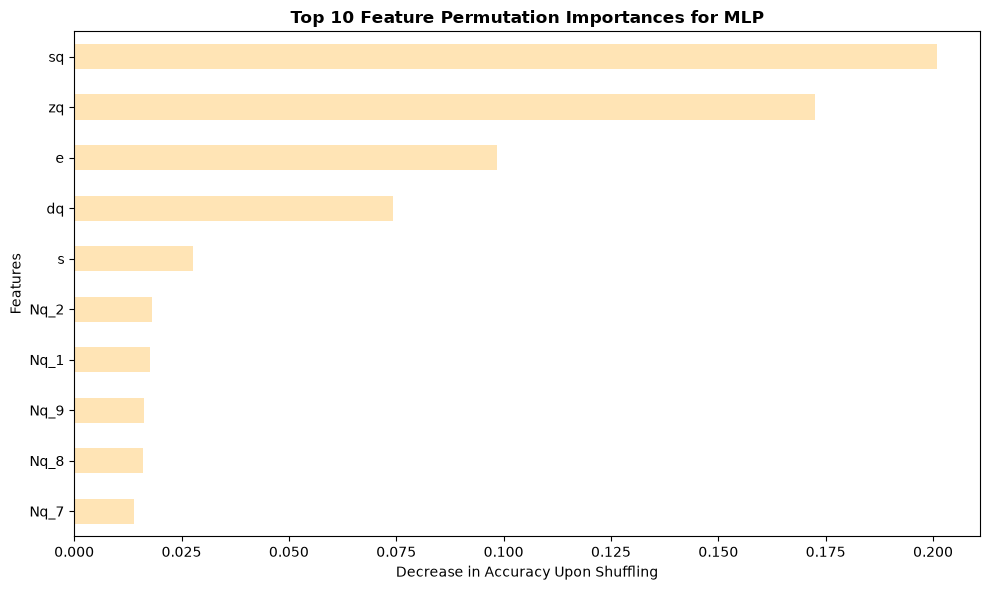

In [ ]:
### --- Feature Permutation Importance Plot for Multilayer Perceptron --- ###
# X_test is a labelled DataFrame at this point (see Section 11.1), so it already carries the feature names.
X_test_df = X_test.copy()

# Calculate the permutation importance on the test set.
result = permutation_importance(
    best_mlp_model,
    X_test_df,
    y_test['polymorphic'],
    n_repeats = 10,
    random_state = random_seed,
    n_jobs = -1
)

# Put the results into a pandas Series and plot the top 10 features, with title and labels.
perm_importances = pd.Series(result.importances_mean, index = X_test_df.columns)
plt.figure(figsize = (10, 6))
perm_importances.nlargest(10).sort_values().plot(kind = 'barh', color = 'moccasin')
plt.title('Top 10 Feature Permutation Importances for MLP', fontweight = 'bold')
plt.xlabel('Decrease in Accuracy Upon Shuffling')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

> **Takeaway.** The MLP does not beat XGBoost and is much harder to interpret, so XGBoost remains our best model.

## **13. Model Comparison and Conclusions**

### **13.1 Comparison of the Models**

The cell below collects the accuracy of every model on the training and test sets, as well as the test AUC, in one table. Additionally it plots all the ROCcurve in one plot allowing visual comparison

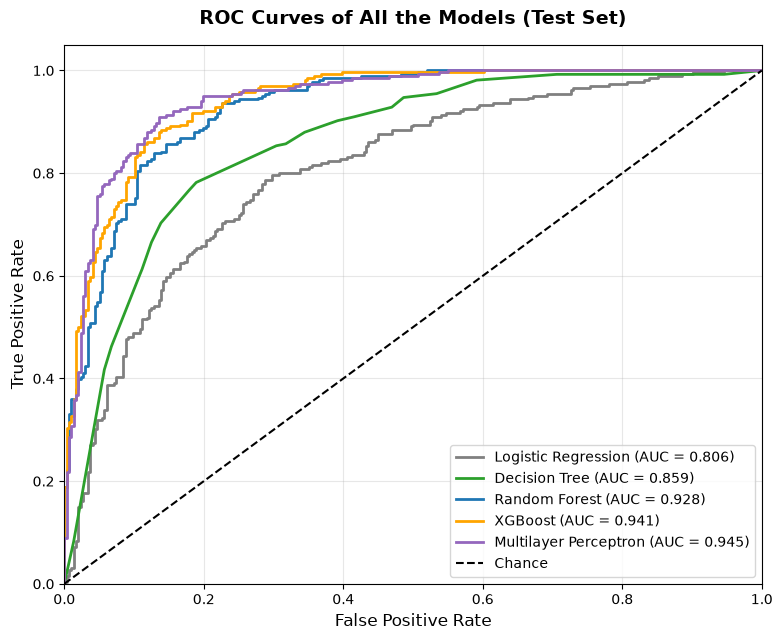

In [ ]:
### --- Model Comparison on the Training and Test Sets --- ###
models = {
    'Logistic Regression': best_log_reg_model,
    'Decision Tree': best_model_dt,
    'Random Forest': best_rf_model,
    'XGBoost': best_xgb_model,
    'Multilayer Perceptron': best_mlp_model,
}

rows = []
for name, model in models.items():
    rows.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train['polymorphic'], model.predict(X_train)),
        'Test Accuracy': accuracy_score(y_test['polymorphic'], model.predict(X_test)),
        'Test AUC': roc_auc_score(y_test['polymorphic'], model.predict_proba(X_test)[:, 1]),
    })

# Display the summary table.
comparison_df = pd.DataFrame(rows).set_index('Model').round(3)
comparison_df

### --- Combined ROC Curves of All the Models --- ###
models = {
    'Logistic Regression': best_log_reg_model,
    'Decision Tree': best_model_dt,
    'Random Forest': best_rf_model,
    'XGBoost': best_xgb_model,
    'Multilayer Perceptron': best_mlp_model,
}

# One colour per model.
colors = ['gray', 'tab:green', 'tab:blue', 'orange', 'tab:purple']

plt.figure(figsize = (9, 7))
for (name, model), color in zip(models.items(), colors):
    # Compute the ROC curve and the AUC of each model on the test set.
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test['polymorphic'], y_proba)
    auc_score = roc_auc_score(y_test['polymorphic'], y_proba)
    plt.plot(fpr, tpr, color = color, lw = 2, label = f'{name} (AUC = {auc_score:.3f})')

# Add the chance line, legend, labels and title.
plt.plot([0, 1], [0, 1], color = 'black', linestyle = '--', label = 'Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('ROC Curves of All the Models (Test Set)', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('False Positive Rate', fontsize = 12)
plt.ylabel('True Positive Rate', fontsize = 12)
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

Test accuracies observed in the reference run:

| Model | Test accuracy | Change vs previous | Interpretability |
|---|---|---|---|
| Logistic regression | 74.6% | baseline | High (linear effects) |
| Decision tree | 79.7% | +5.2 points | Very high (readable rules) |
| Random forest | 84.9% | +5.2 points | Low (importance only) |
| **XGBoost** | **88.4%** | **+3.6 points** | Medium (with SHAP) |
| Multilayer perceptron | 87.4% | -0.9 points | Low |

### **13.2 Conclusions**

1. **The problem is non-linear.** Moving from a linear model (about 75%) to tree-based models (80% to 88%) shows that the relationship between the life-history parameters and polymorphism involves thresholds and interactions.
2. **XGBoost is the best compromise.** It is the most accurate model (about 88%), and SHAP keeps it interpretable. The more flexible MLP brings no gain.
3. **Three parameters dominate.** The effect of the allele (`sq`), the phenotype of the castes (`zq`) and the colony extinction rate (`e`) explain most of the predictions. The number of queens (especially single-queen colonies) and the survival rate come next, whereas the number of males and the migration rate matter little.
4. **Dominance acts through interactions.** `dq` and `dw` have a modest direct effect but interact with the sign of `sq`. The pattern, however, does not follow the simple dominance-reversal expectation, and may be worth a closer look.

### **13.3 Limitations and Next Steps**

- **Binary target.** The classification ignores *how frequent* polymorphism is. A **hurdle model** (classifier followed by a regressor trained on polymorphic cases) would recover this information.
- **Threshold choice.** A parameter set counts as polymorphic as soon as one replicate out of 100 keeps the allele. A stricter threshold would define a different, perhaps more robust, target; `polymorph_threshold` makes this easy to test.
- **Categorical coding of `Nq` and `Nm`.** One-hot encoding ignores the fact that these counts are ordered. It is flexible, but it spreads their importance over many columns.
- **Single split.** The test set contains 562 samples, so its accuracies carry a standard error of about 1.4 percentage points. The differences between XGBoost and the MLP are within that margin; repeated cross-validation would give firmer rankings.
- **Remaining overfitting.** The tree ensembles and the MLP still show a gap of several points between training and test accuracy, even after regularisation.